# Heart Disease Risk Modeling Workflow
## Applied MLOps Notebook

**Dataset:** UCI heart disease archive  
**Focus:** Build a reproducible prediction pipeline covering data review, preprocessing, model validation, experiment tracking, API serving, and deployment monitoring.

## 0. Notebook setup

This workbook is organized around a compact clinical prediction workflow and is intended to run from the project root folder.

In [ ]:
from pathlib import Path
import sys
import os
import json
import subprocess
import importlib.util

PROJECT_ROOT = Path.cwd()
print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Project root:", PROJECT_ROOT)
print("requirements.txt exists:", (PROJECT_ROOT / "requirements.txt").exists())
print("download_data.py exists:", (PROJECT_ROOT / "download_data.py").exists())

if not (PROJECT_ROOT / "requirements.txt").exists() or not (PROJECT_ROOT / "download_data.py").exists():
    raise FileNotFoundError(
        "Open this notebook from the project root folder containing requirements.txt and download_data.py."
    )

Python: 3.11.9 (v3.11.9:de54cf5be3, Apr  2 2024, 07:12:50) [Clang 13.0.0 (clang-1300.0.29.30)]
Python executable: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/.venv/bin/python
Project root: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease
requirements.txt exists: True
download_data.py exists: True


In [ ]:
# Install the project's pinned dependencies into the active notebook kernel.
# Run this cell when setting up a fresh environment; it is safe to rerun if needed.
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Verify the key packages after installation.
import pandas as pd
import numpy as np
import sklearn
import mlflow
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)

Python: 3.11.9
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.5.2
MLflow: 2.17.2


# Stage 1 — Data collection and exploratory review

This section downloads the clinical dataset, validates the source format, and applies the project-level cleaning logic. The data preparation step standardizes field names, resolves missing-value markers, converts fields to usable numeric types, and transforms the original diagnosis label into a binary target where 0 indicates no disease and 1 indicates a positive case.

In [ ]:
!open "/Applications/Python 3.11/Install Certificates.command"

In [ ]:
import ssl
import certifi
import subprocess
import sys
from pathlib import Path

print("Python:", sys.version)
print("Default SSL certificate paths:", ssl.get_default_verify_paths())
print("certifi certificate bundle:", certifi.where())
print("Certificate bundle exists:", Path(certifi.where()).exists())

# Configure this notebook's Python process to use certifi's CA bundle
import os
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

print("\nSSL certificate configuration applied to this notebook.")

Python: 3.11.9 (v3.11.9:de54cf5be3, Apr  2 2024, 07:12:50) [Clang 13.0.0 (clang-1300.0.29.30)]
Default SSL certificate paths: DefaultVerifyPaths(cafile='/Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/.venv/lib/python3.11/site-packages/certifi/cacert.pem', capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='/Library/Frameworks/Python.framework/Versions/3.11/etc/openssl/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='/Library/Frameworks/Python.framework/Versions/3.11/etc/openssl/certs')
certifi certificate bundle: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/.venv/lib/python3.11/site-packages/certifi/cacert.pem
Certificate bundle exists: True

SSL certificate configuration applied to this notebook.


In [ ]:
import subprocess
import sys
from pathlib import Path

result = subprocess.run(
    [sys.executable, "download_data.py"],
    cwd=Path.cwd(),
    capture_output=True,
    text=True,
    env=__import__("os").environ.copy()
)

print("Exit code:", result.returncode)
print(result.stdout)
print(result.stderr[-3000:] if result.stderr else "No error output")

Exit code: 0
Saved 303 rows to data/raw/heart_disease.csv
   age  sex  cp  trestbps  chol  fbs  ...  exang  oldpeak  slope   ca  thal  target
0   63    1   1       145   233    1  ...      0      2.3      3  0.0   6.0       0
1   67    1   4       160   286    0  ...      1      1.5      2  3.0   3.0       1
2   67    1   4       120   229    0  ...      1      2.6      2  2.0   7.0       1
3   37    1   3       130   250    0  ...      0      3.5      3  0.0   3.0       0
4   41    0   2       130   204    0  ...      0      1.4      1  0.0   3.0       0

[5 rows x 14 columns]

No error output


In [ ]:
import subprocess
import sys
from pathlib import Path

result = subprocess.run(
    [sys.executable, "-m", "src.eda"],
    cwd=Path.cwd(),
    capture_output=True,
    text=True,
    env=__import__("os").environ.copy()
)

print("Exit code:", result.returncode)
print(result.stdout)

if result.stderr:
    print("Messages / errors:")
    print(result.stderr[-3000:])

if result.returncode != 0:
    raise RuntimeError("EDA failed. Check the messages above.")

Exit code: 0
{
  "rows": 303,
  "columns_including_target": 14,
  "missing_values_by_column": {
    "age": 0,
    "trestbps": 0,
    "chol": 0,
    "thalach": 0,
    "oldpeak": 0,
    "sex": 0,
    "cp": 0,
    "fbs": 0,
    "restecg": 0,
    "exang": 0,
    "slope": 0,
    "ca": 4,
    "thal": 2,
    "target": 0
  },
  "class_counts": {
    "0": 164,
    "1": 139
  },
  "descriptive_statistics": {
    "age": {
      "count": 303.0,
      "mean": 54.439,
      "std": 9.039,
      "min": 29.0,
      "25%": 48.0,
      "50%": 56.0,
      "75%": 61.0,
      "max": 77.0
    },
    "trestbps": {
      "count": 303.0,
      "mean": 131.69,
      "std": 17.6,
      "min": 94.0,
      "25%": 120.0,
      "50%": 130.0,
      "75%": 140.0,
      "max": 200.0
    },
    "chol": {
      "count": 303.0,
      "mean": 246.693,
      "std": 51.777,
      "min": 126.0,
      "25%": 211.0,
      "50%": 241.0,
      "75%": 275.0,
      "max": 564.0
    },
    "thalach": {
      "count": 303.0,
      "me

Number of plots: 5
boxplots_numeric.png


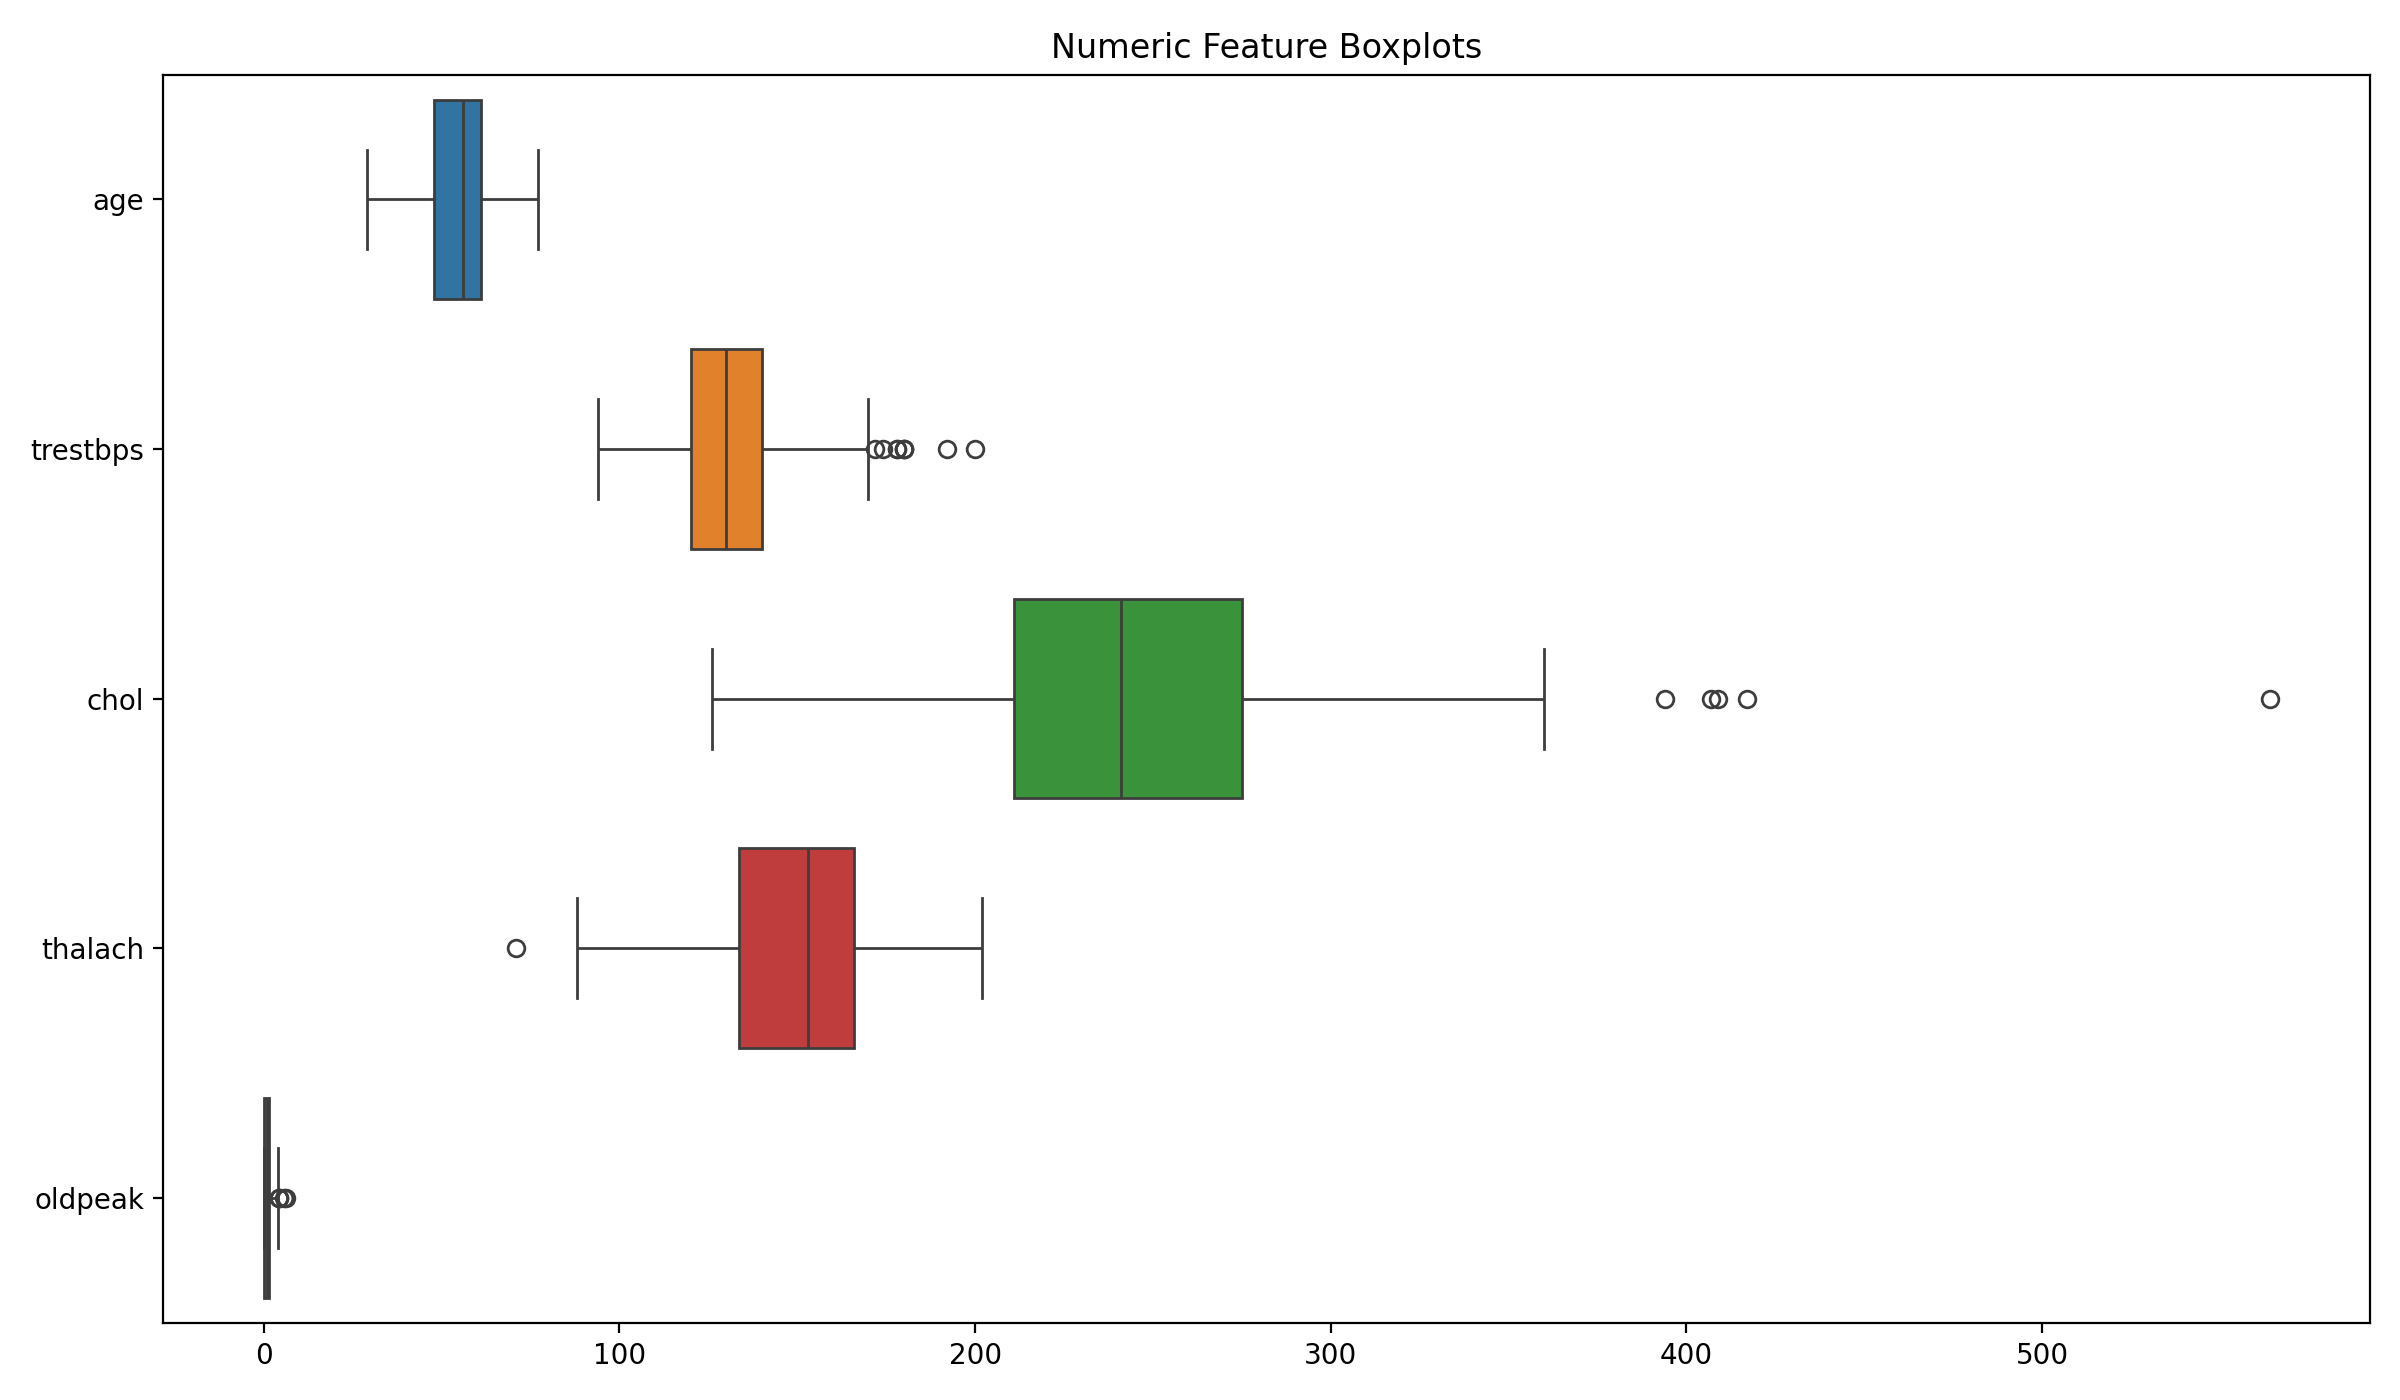

class_balance.png


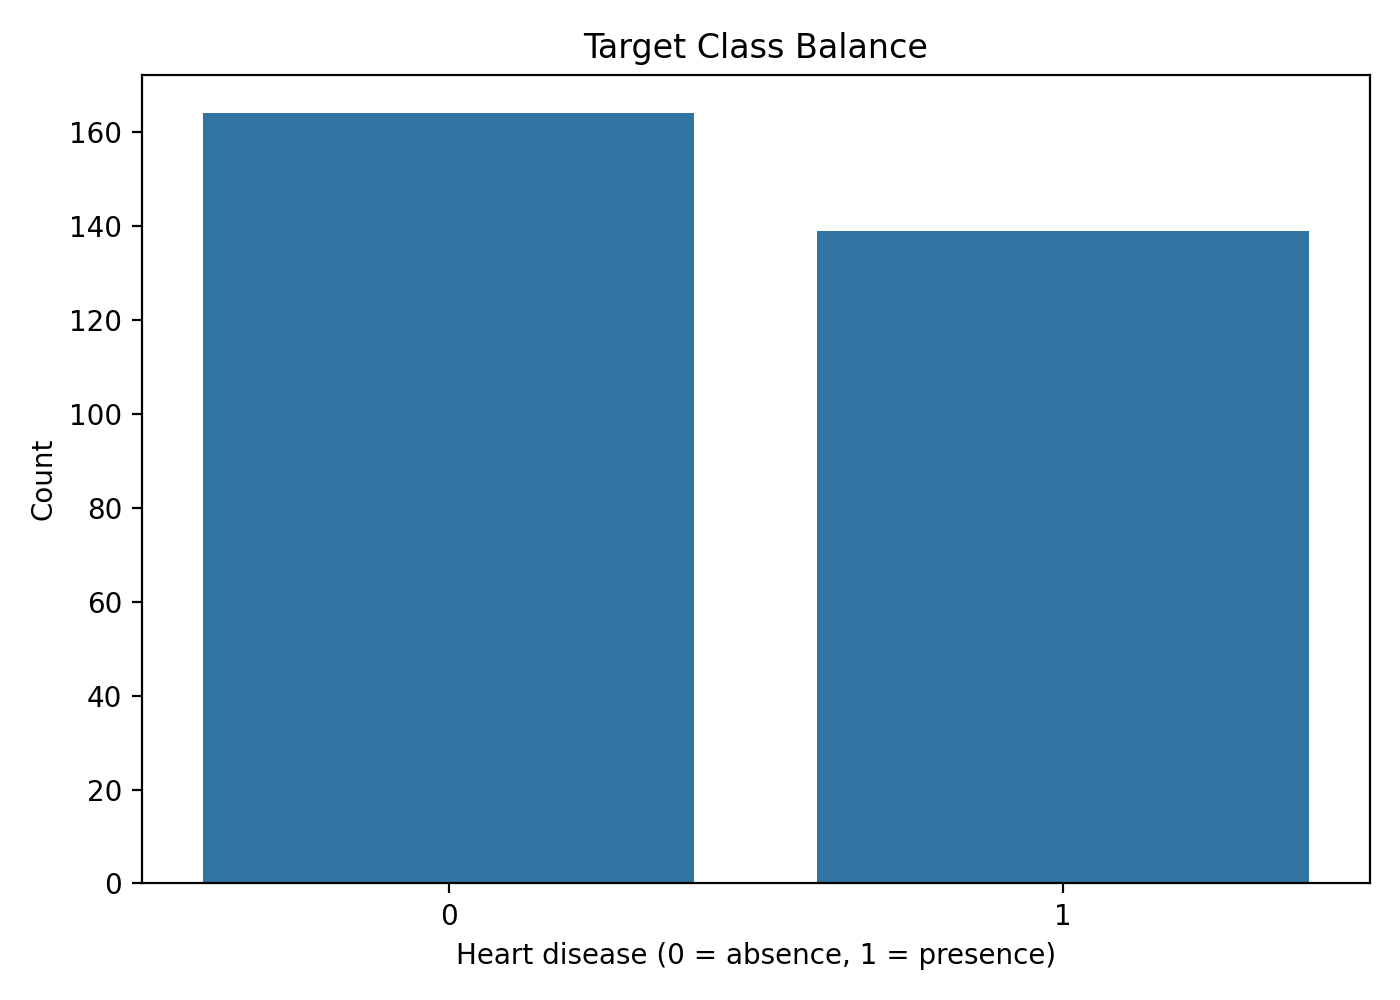

correlation_heatmap.png


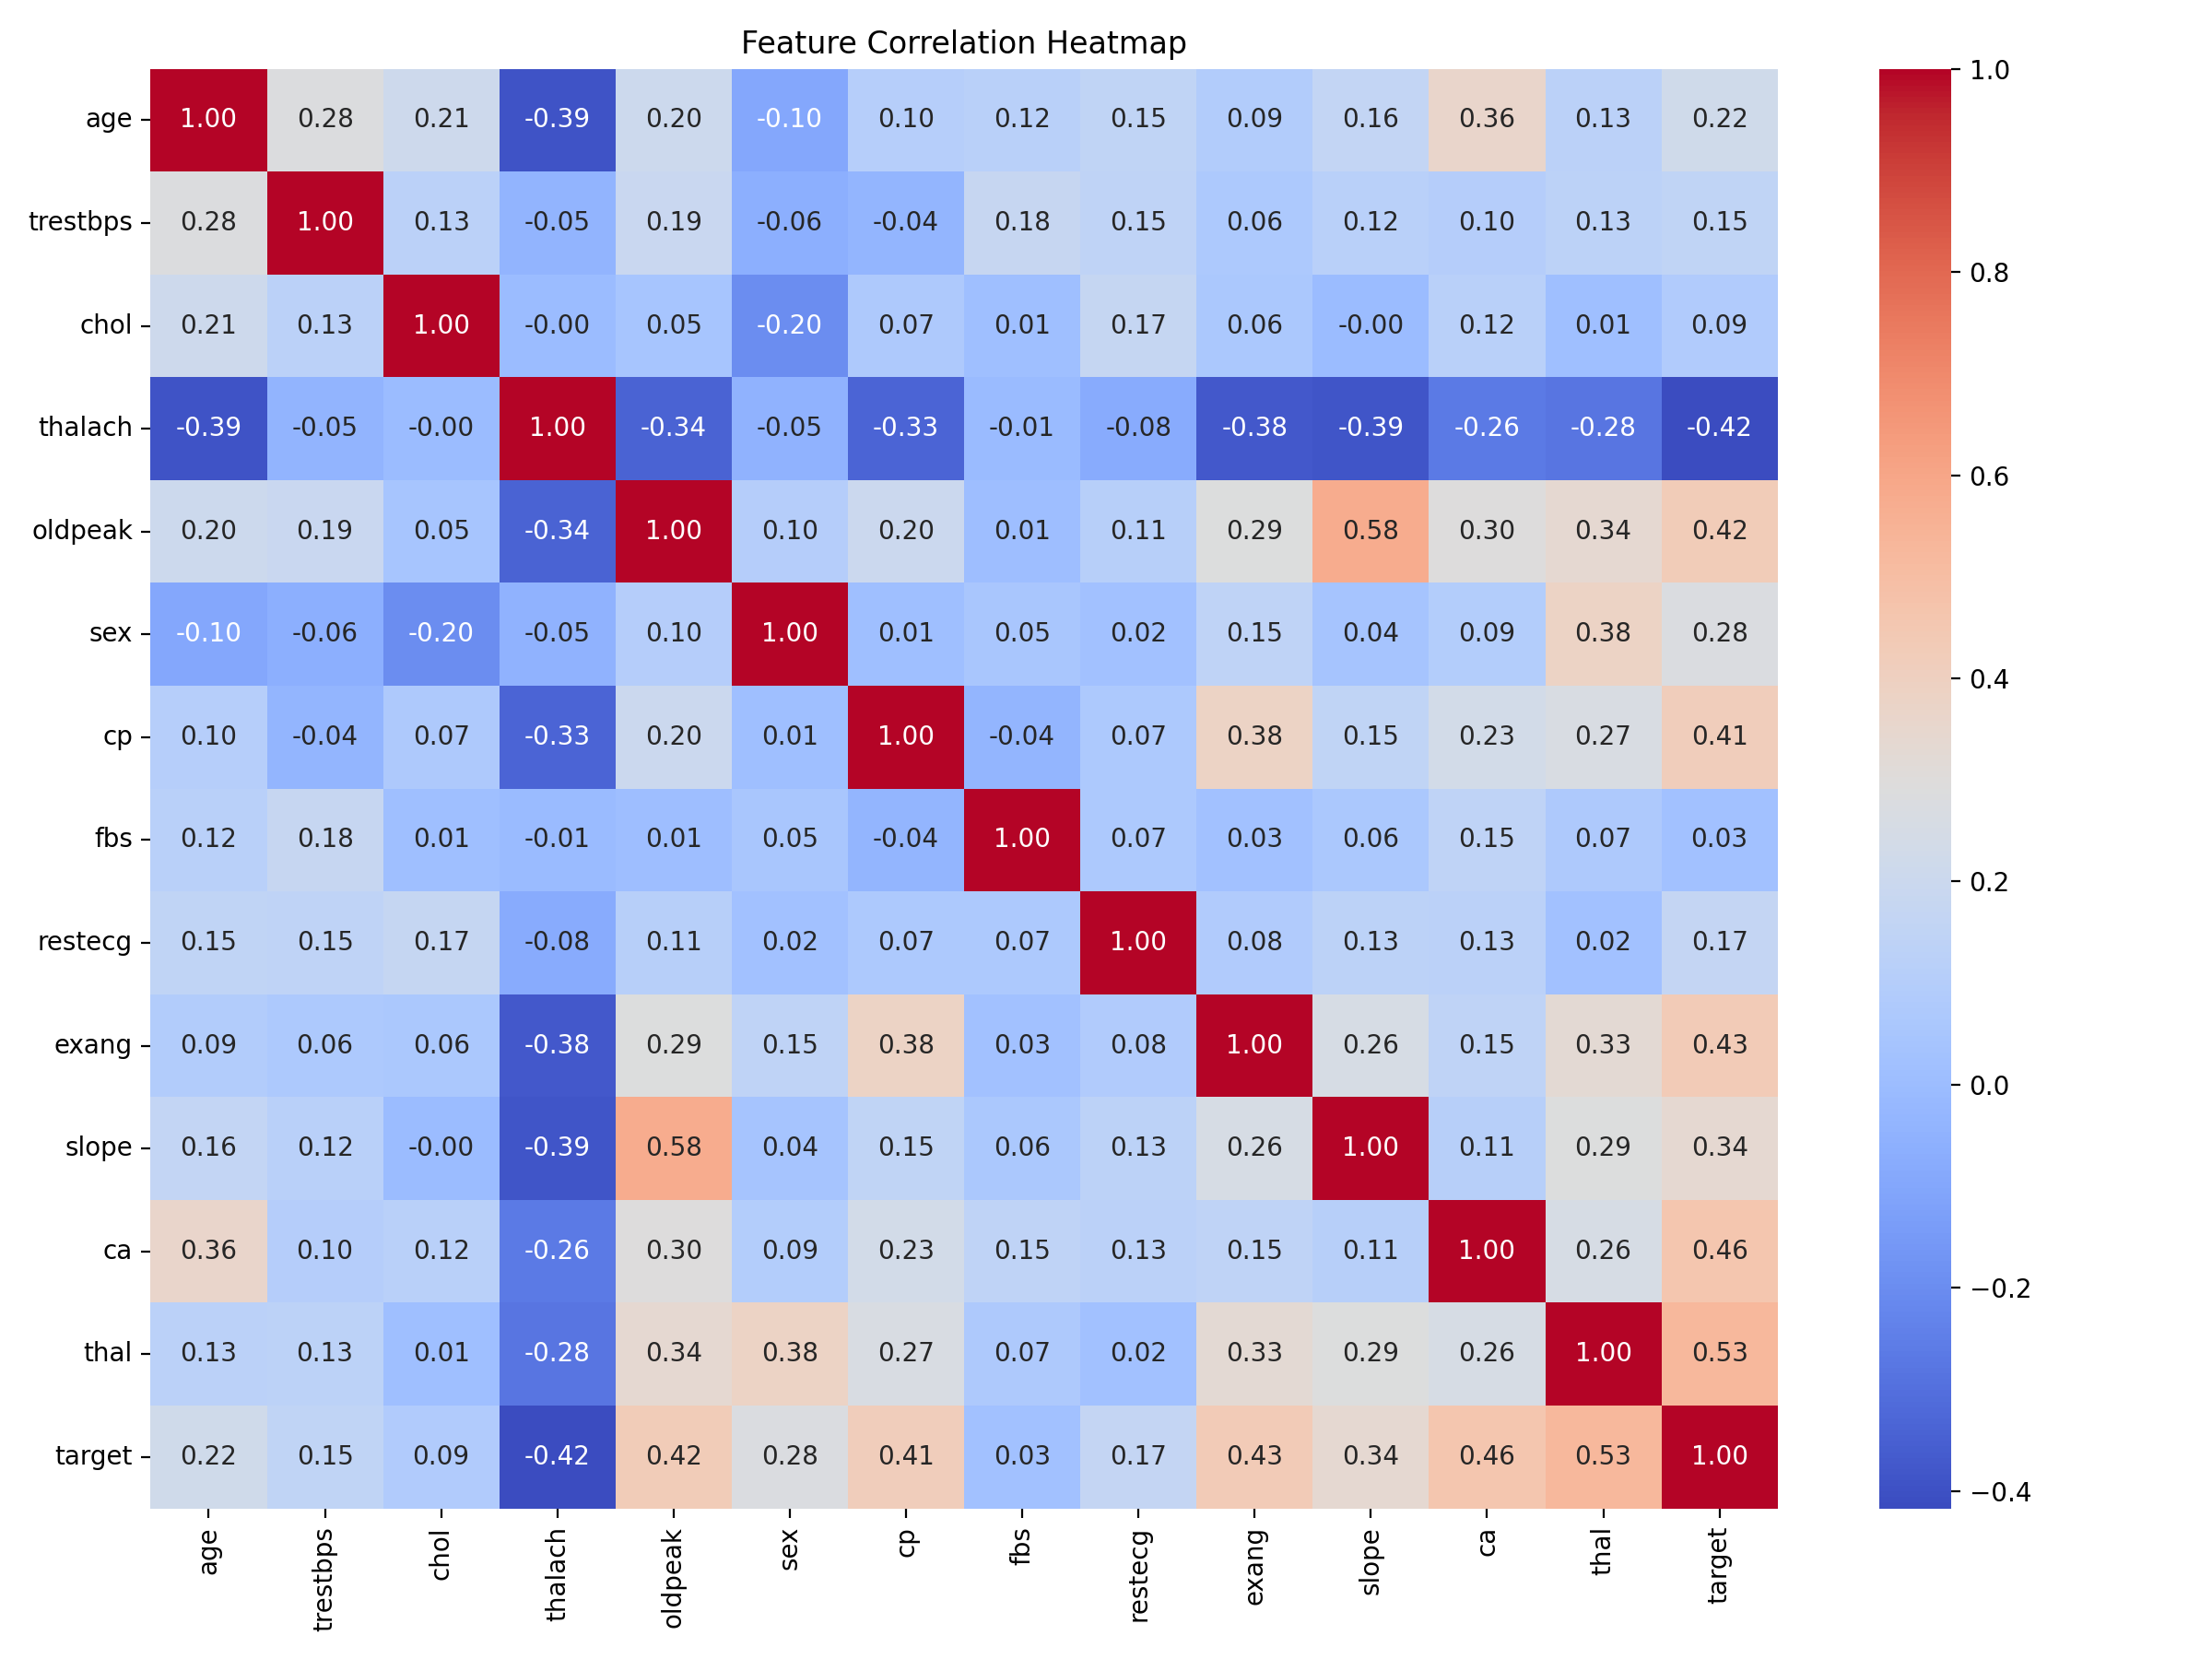

feature_histograms.png


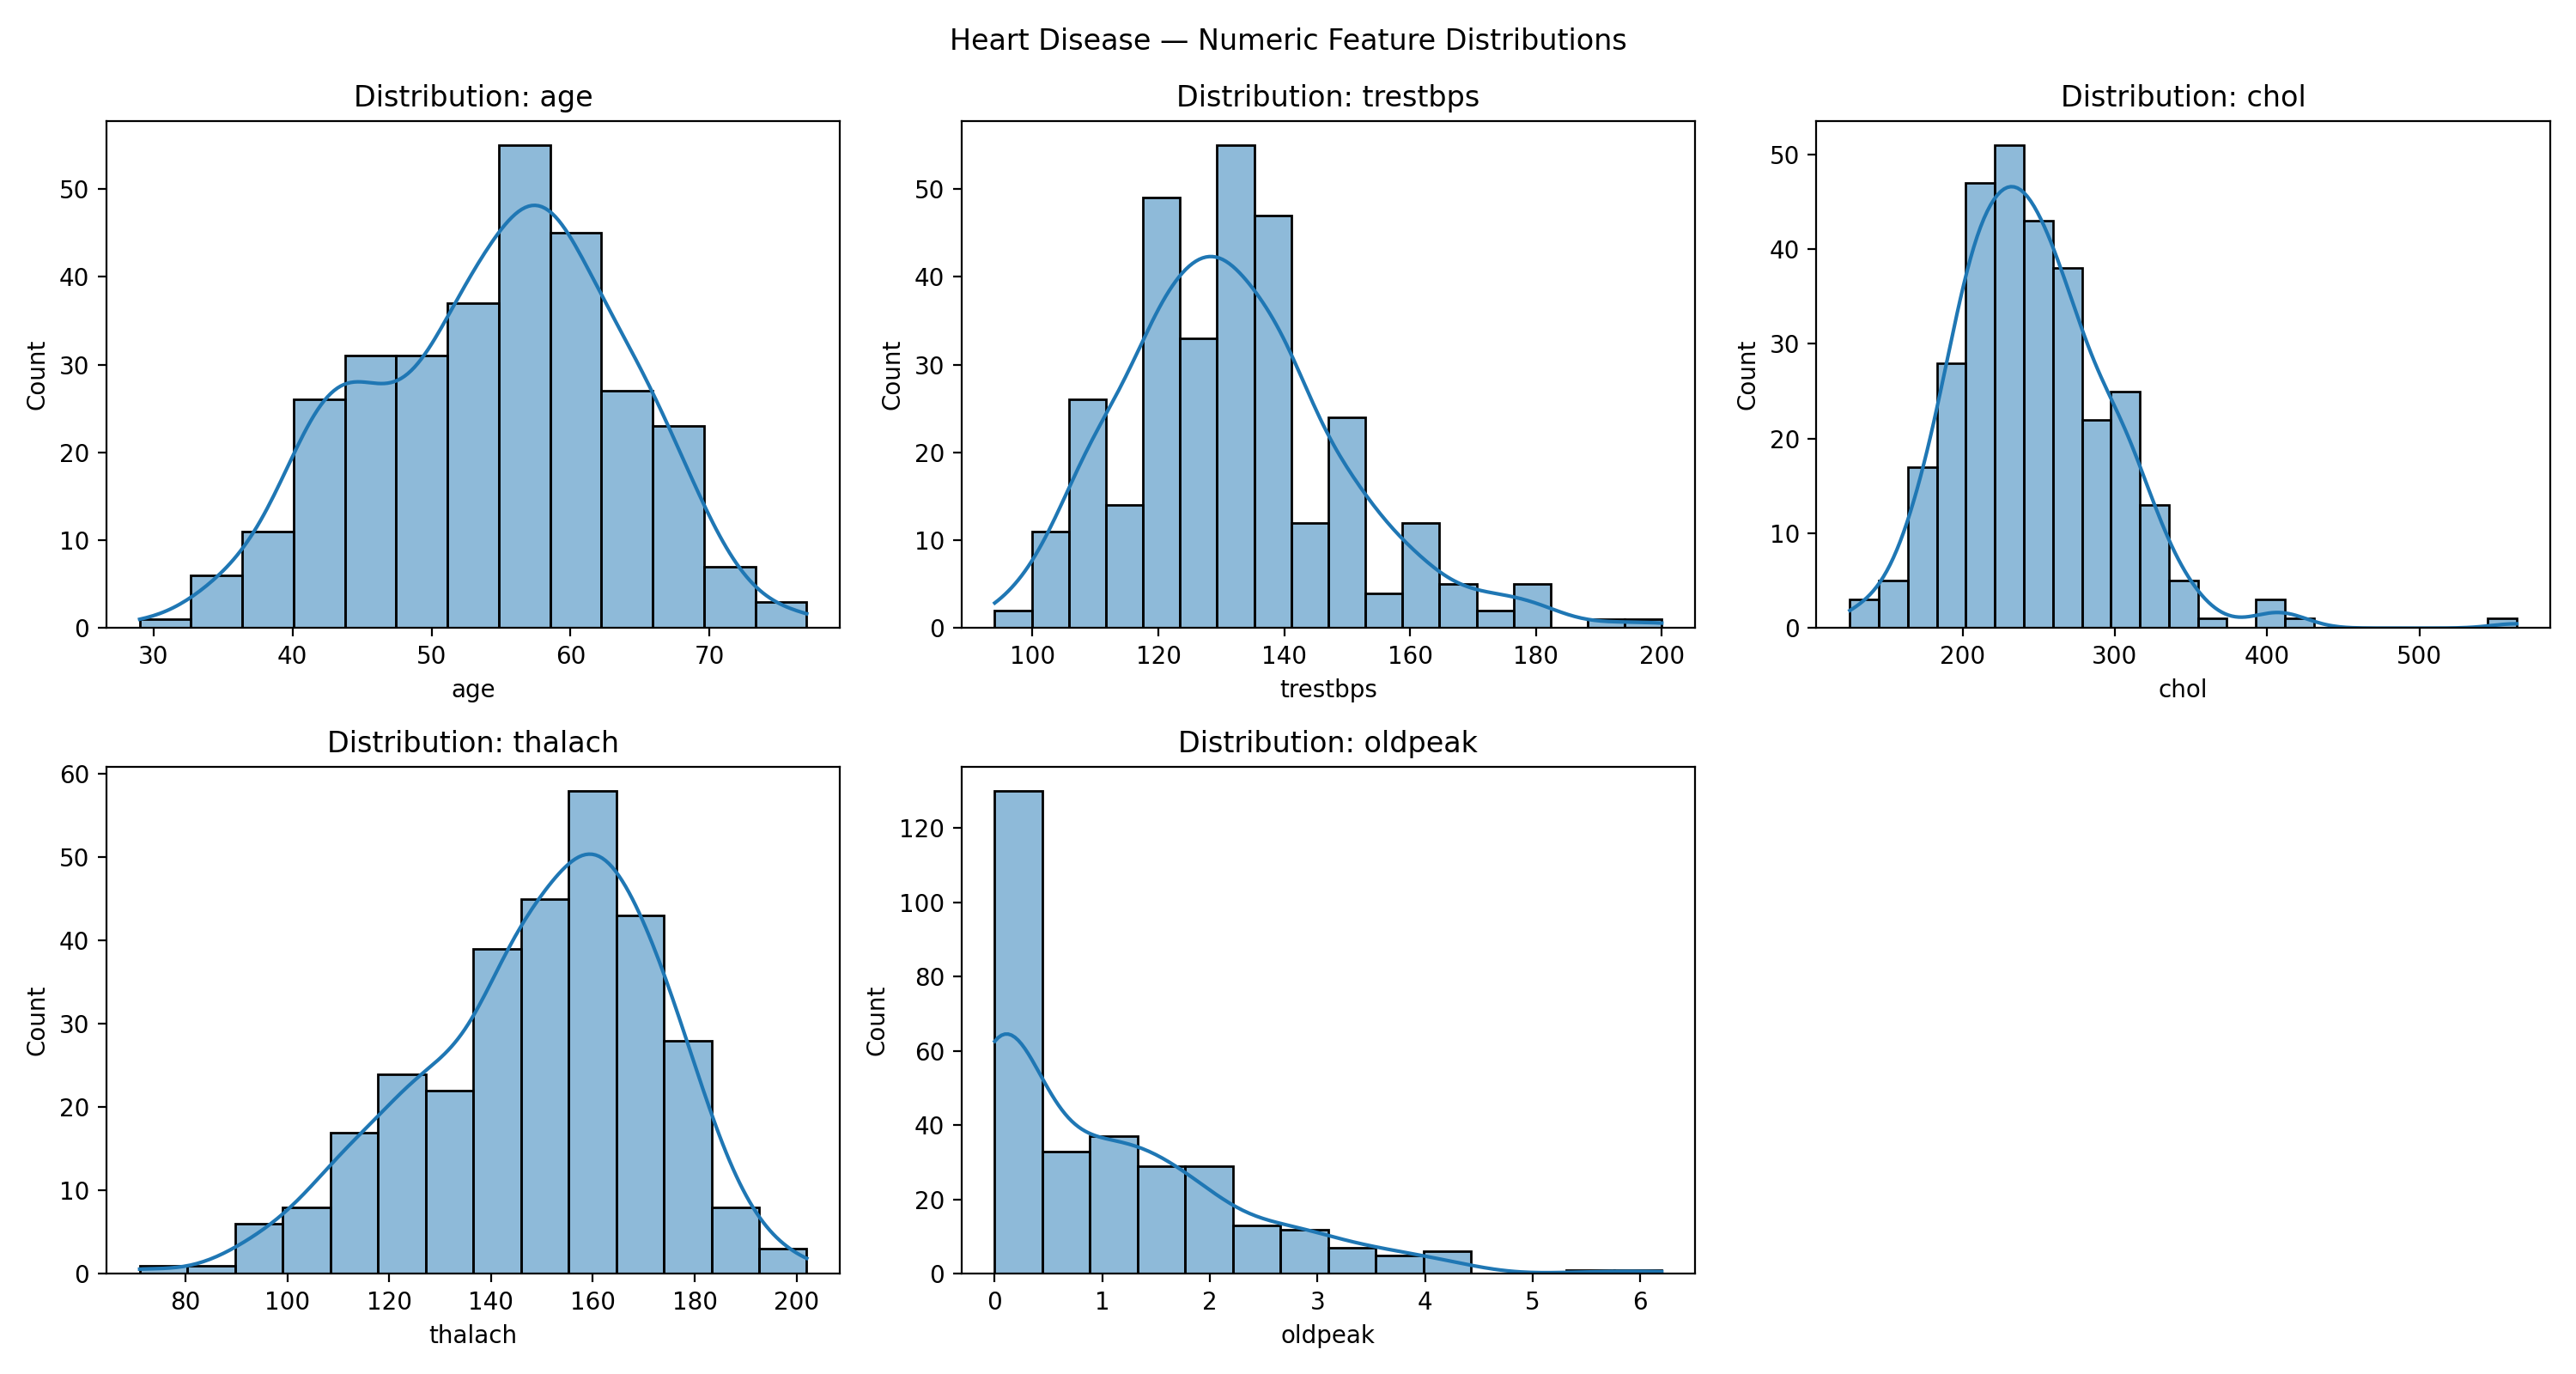

roc_curves.png


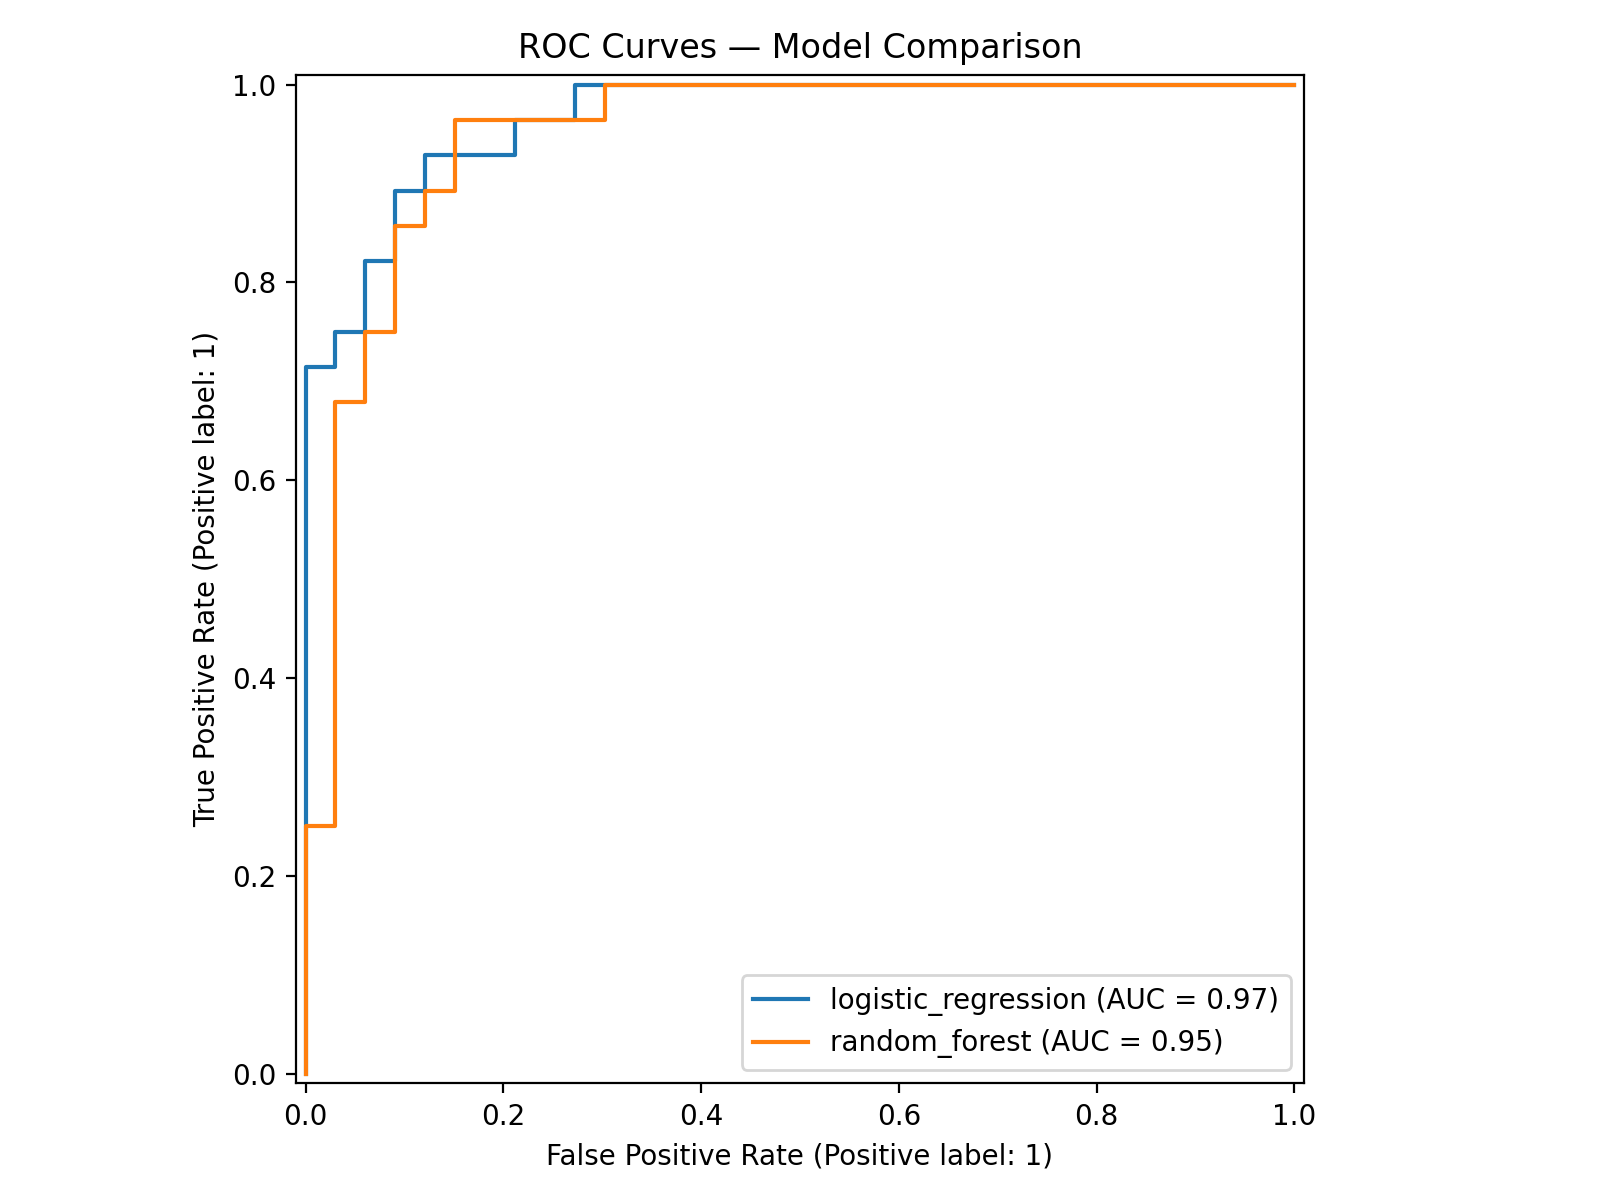

In [ ]:
from pathlib import Path
from IPython.display import display, Image

plot_dir = Path("artifacts/plots")

if not plot_dir.exists():
    print("Plot directory not found:", plot_dir.resolve())
else:
    plots = list(sorted(plot_dir.glob("*.png")))
    print("Number of plots:", len(plots))

    for plot in plots:
        print(plot.name)
        display(Image(filename=str(plot)))

In [ ]:
# 1.2 Inspect the downloaded files.
for path in sorted((PROJECT_ROOT / "data").rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT), f"({path.stat().st_size:,} bytes)")

data/processed/heart_disease_clean.csv (12,475 bytes)
data/raw/heart_disease.csv (12,475 bytes)
data/raw/heart_disease_metadata.json (570 bytes)


In [ ]:
# 1.3 Run the project's cleaning and EDA pipeline.
result = subprocess.run(
    [sys.executable, "-m", "src.eda"],
    cwd=PROJECT_ROOT,
    text=True,
    capture_output=True
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"EDA failed with exit code {result.returncode}")

{
  "rows": 303,
  "columns_including_target": 14,
  "missing_values_by_column": {
    "age": 0,
    "trestbps": 0,
    "chol": 0,
    "thalach": 0,
    "oldpeak": 0,
    "sex": 0,
    "cp": 0,
    "fbs": 0,
    "restecg": 0,
    "exang": 0,
    "slope": 0,
    "ca": 4,
    "thal": 2,
    "target": 0
  },
  "class_counts": {
    "0": 164,
    "1": 139
  },
  "descriptive_statistics": {
    "age": {
      "count": 303.0,
      "mean": 54.439,
      "std": 9.039,
      "min": 29.0,
      "25%": 48.0,
      "50%": 56.0,
      "75%": 61.0,
      "max": 77.0
    },
    "trestbps": {
      "count": 303.0,
      "mean": 131.69,
      "std": 17.6,
      "min": 94.0,
      "25%": 120.0,
      "50%": 130.0,
      "75%": 140.0,
      "max": 200.0
    },
    "chol": {
      "count": 303.0,
      "mean": 246.693,
      "std": 51.777,
      "min": 126.0,
      "25%": 211.0,
      "50%": 241.0,
      "75%": 275.0,
      "max": 564.0
    },
    "thalach": {
      "count": 303.0,
      "mean": 149.607,

{
  "rows": 303,
  "columns_including_target": 14,
  "missing_values_by_column": {
    "age": 0,
    "trestbps": 0,
    "chol": 0,
    "thalach": 0,
    "oldpeak": 0,
    "sex": 0,
    "cp": 0,
    "fbs": 0,
    "restecg": 0,
    "exang": 0,
    "slope": 0,
    "ca": 4,
    "thal": 2,
    "target": 0
  },
  "class_counts": {
    "0": 164,
    "1": 139
  },
  "descriptive_statistics": {
    "age": {
      "count": 303.0,
      "mean": 54.439,
      "std": 9.039,
      "min": 29.0,
      "25%": 48.0,
      "50%": 56.0,
      "75%": 61.0,
      "max": 77.0
    },
    "trestbps": {
      "count": 303.0,
      "mean": 131.69,
      "std": 17.6,
      "min": 94.0,
      "25%": 120.0,
      "50%": 130.0,
      "75%": 140.0,
      "max": 200.0
    },
    "chol": {
      "count": 303.0,
      "mean": 246.693,
      "std": 51.777,
      "min": 126.0,
      "25%": 211.0,
      "50%": 241.0,
      "75%": 275.0,
      "max": 564.0
    },
    "thalach": {
      "count": 303.0,
      "mean": 149.607,

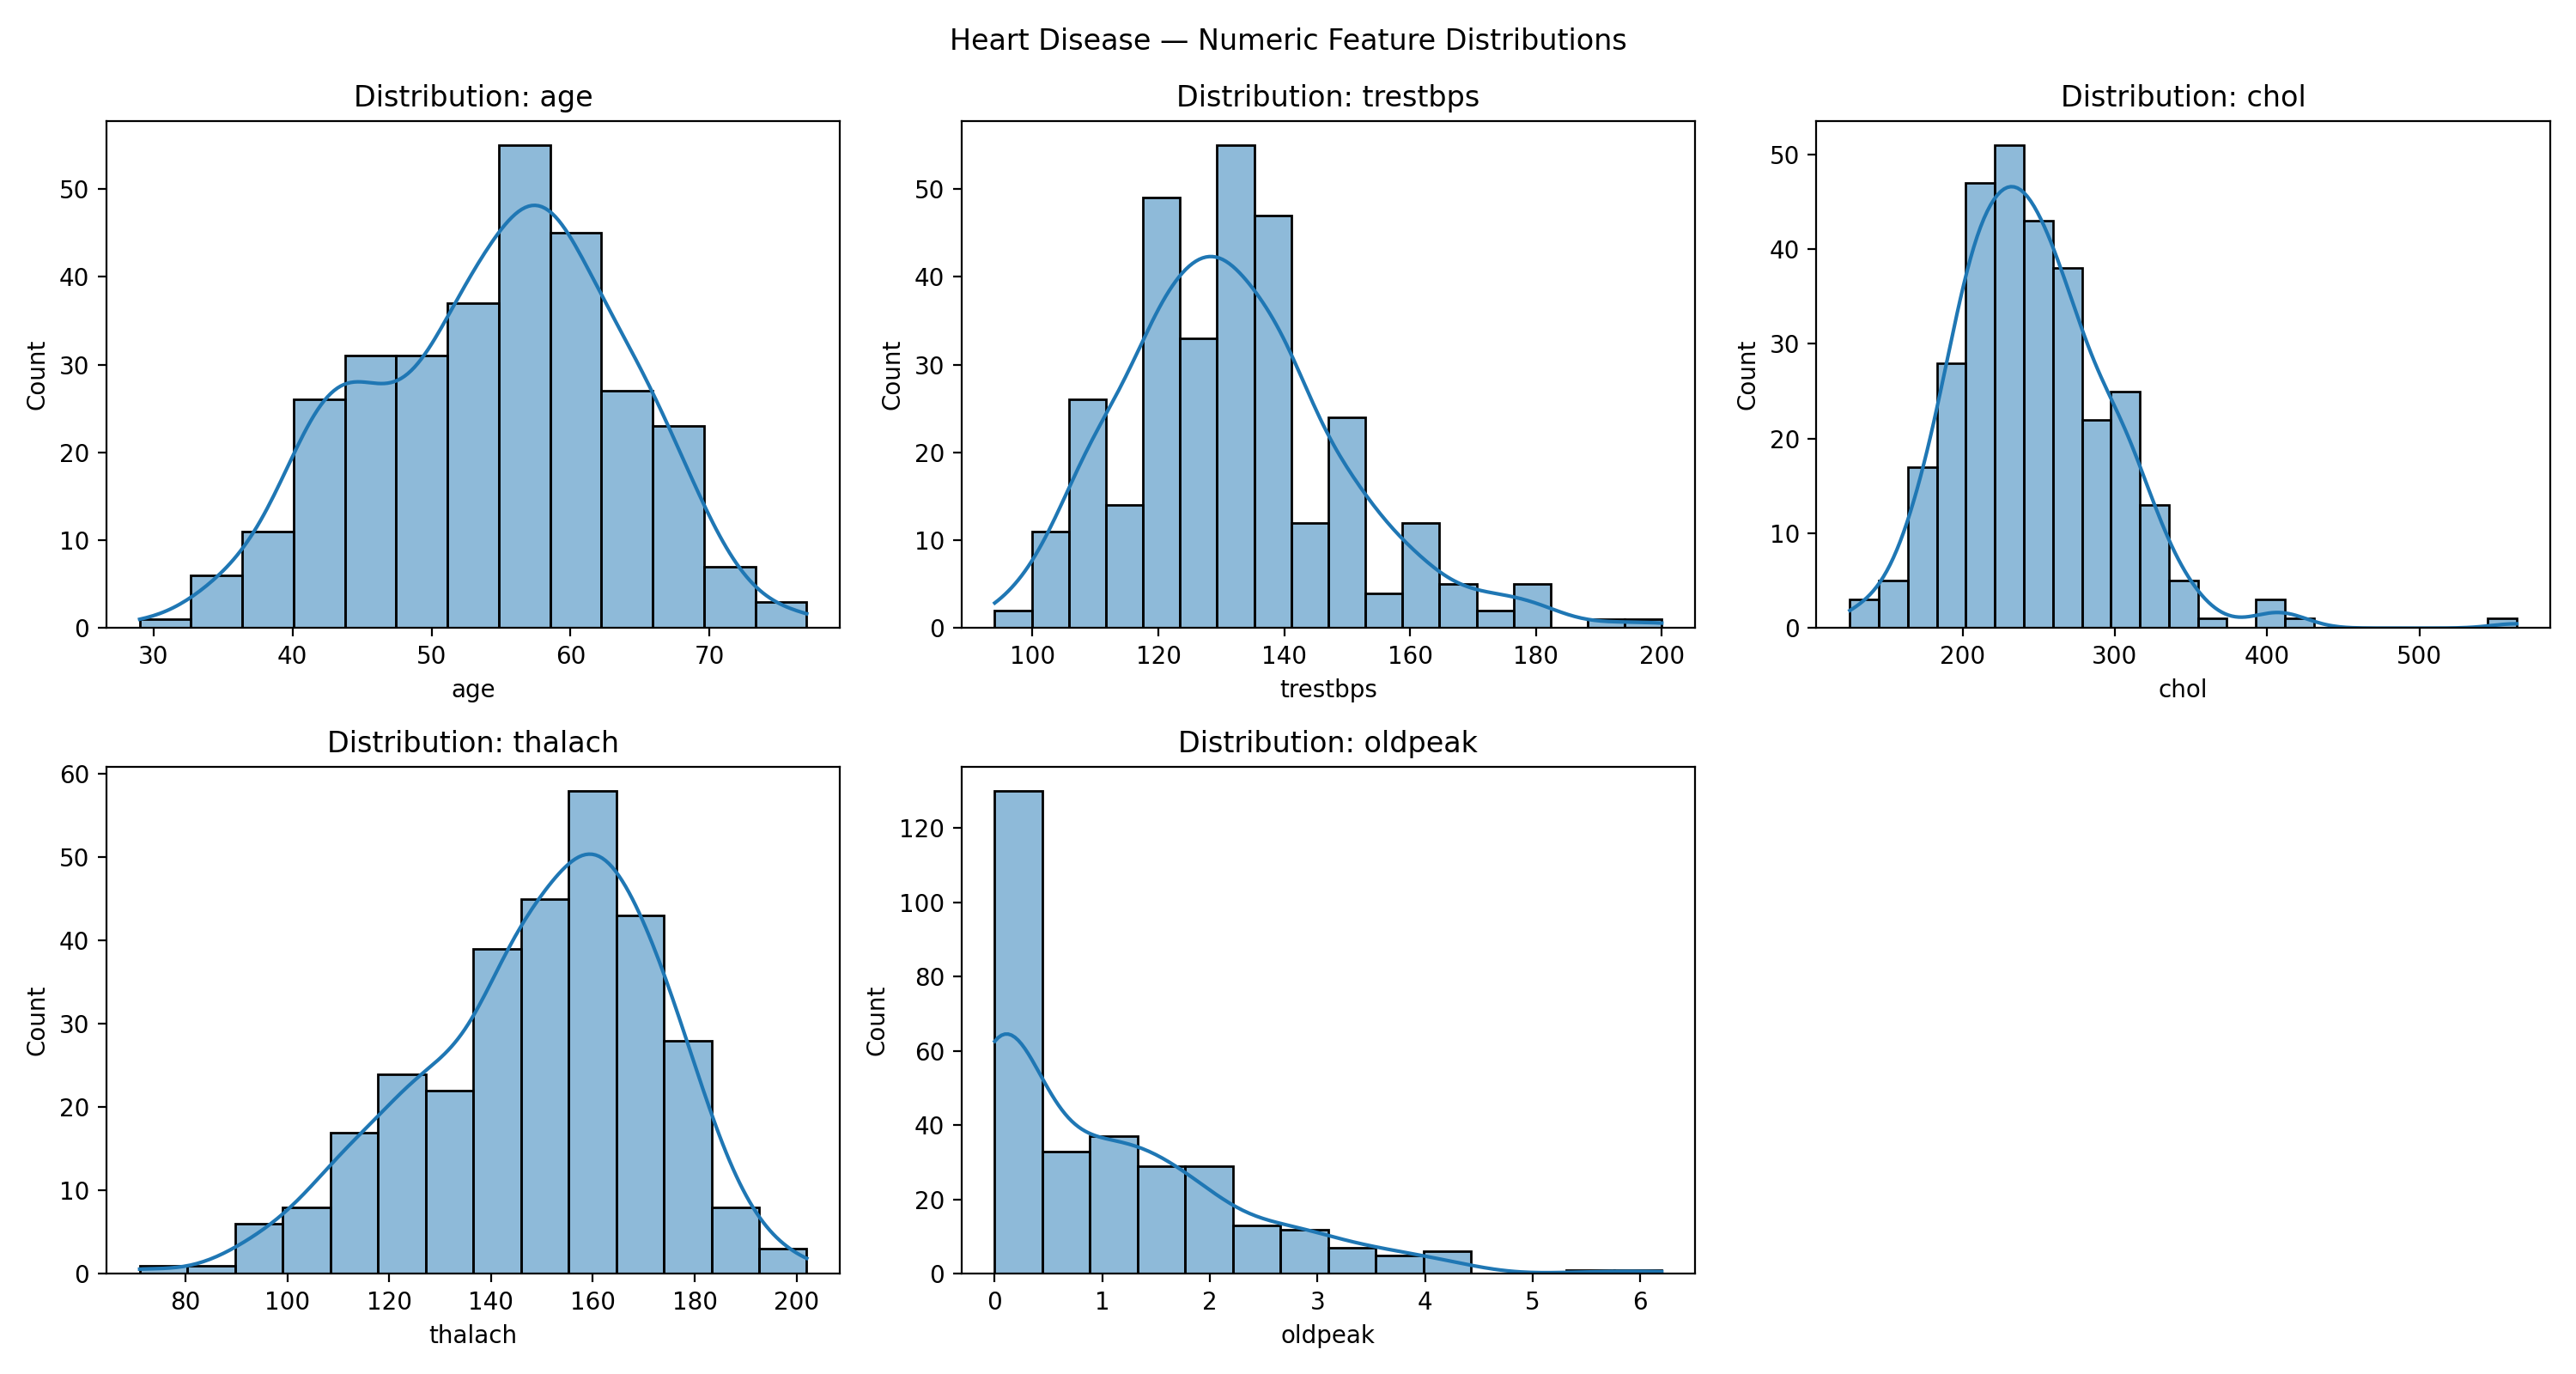

correlation_heatmap.png


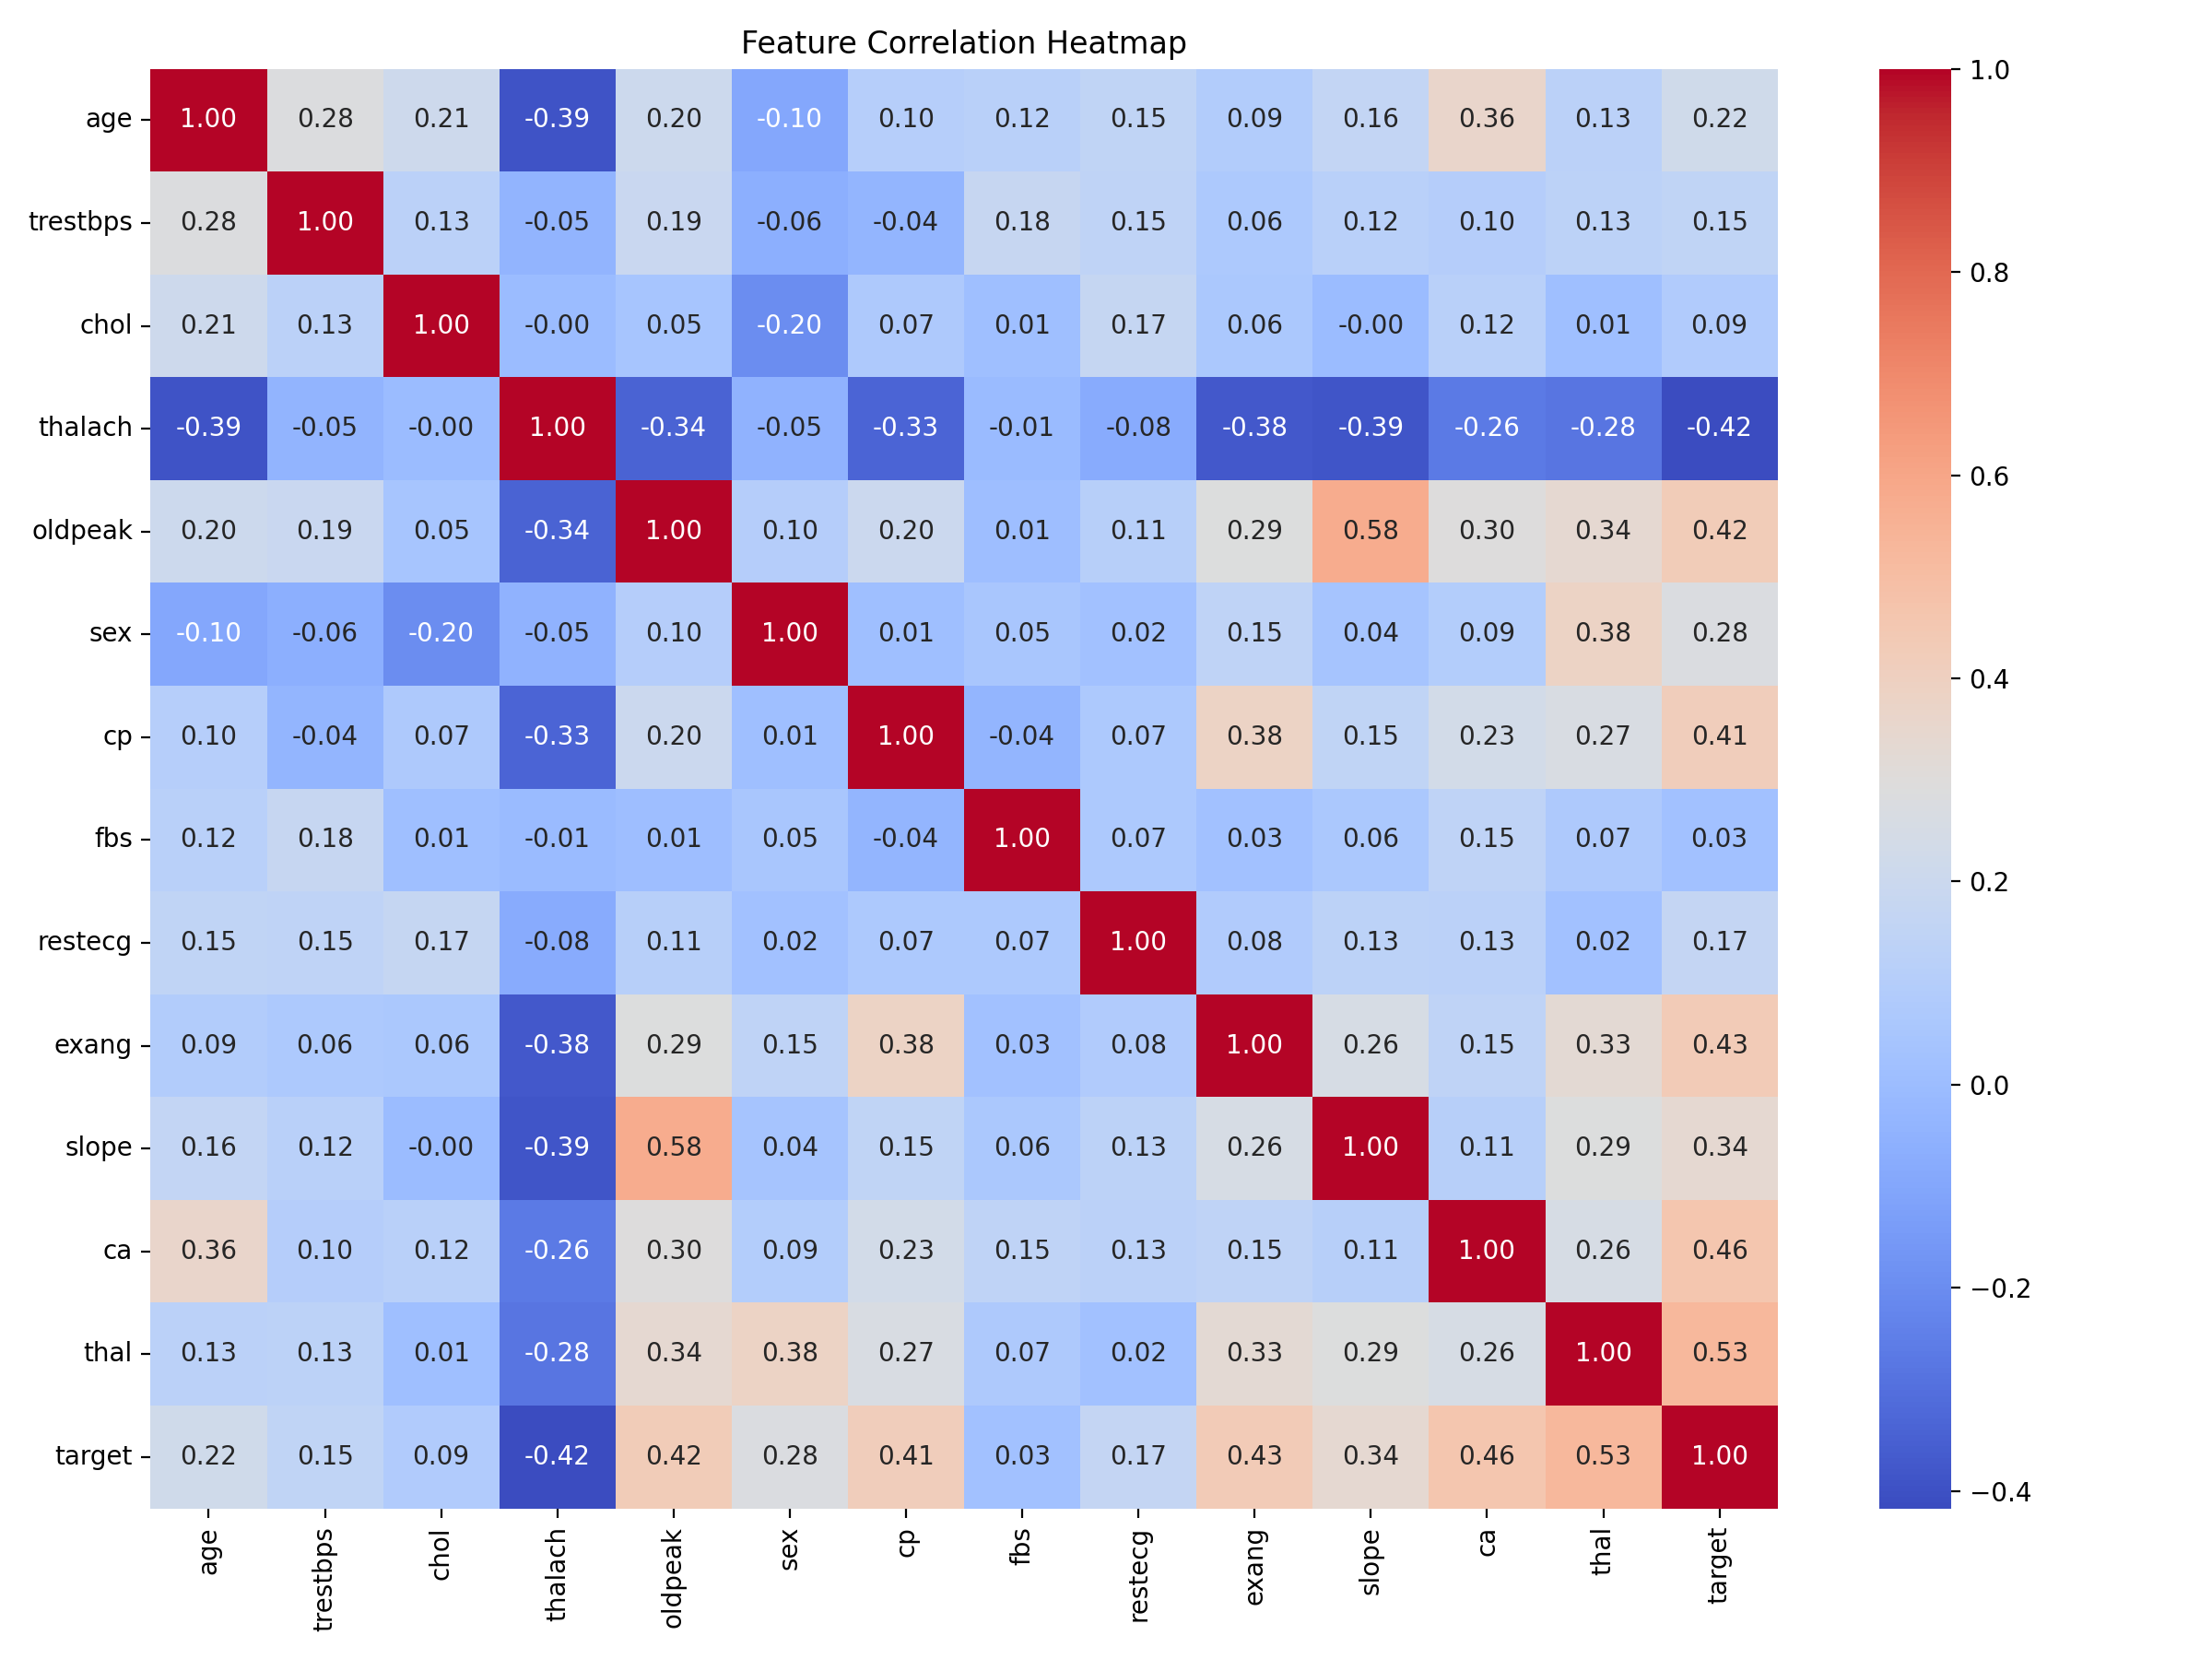

class_balance.png


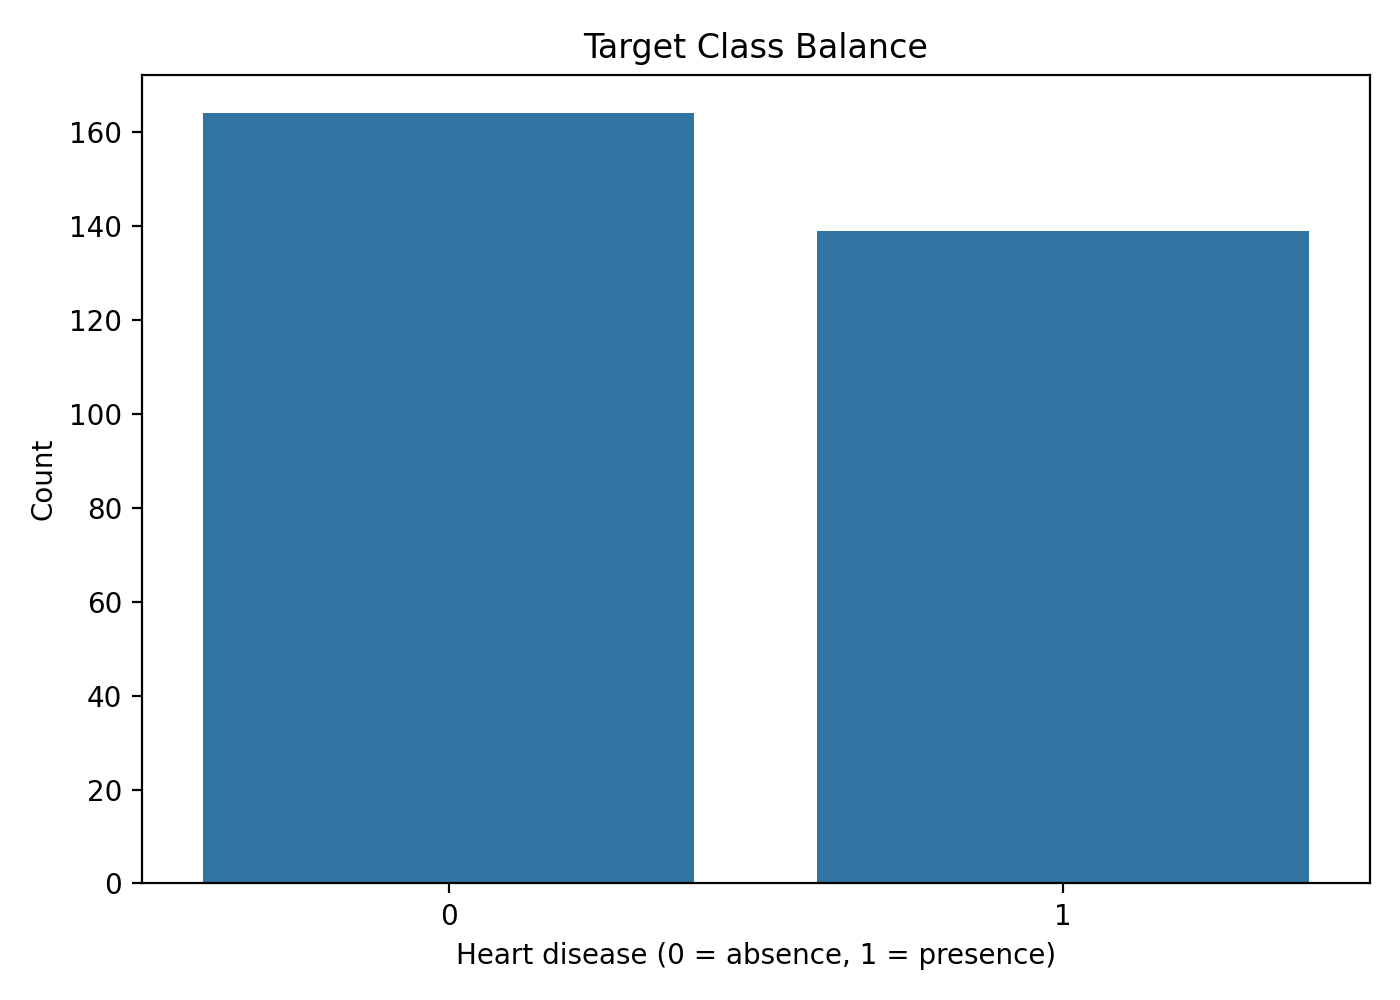

boxplots_numeric.png


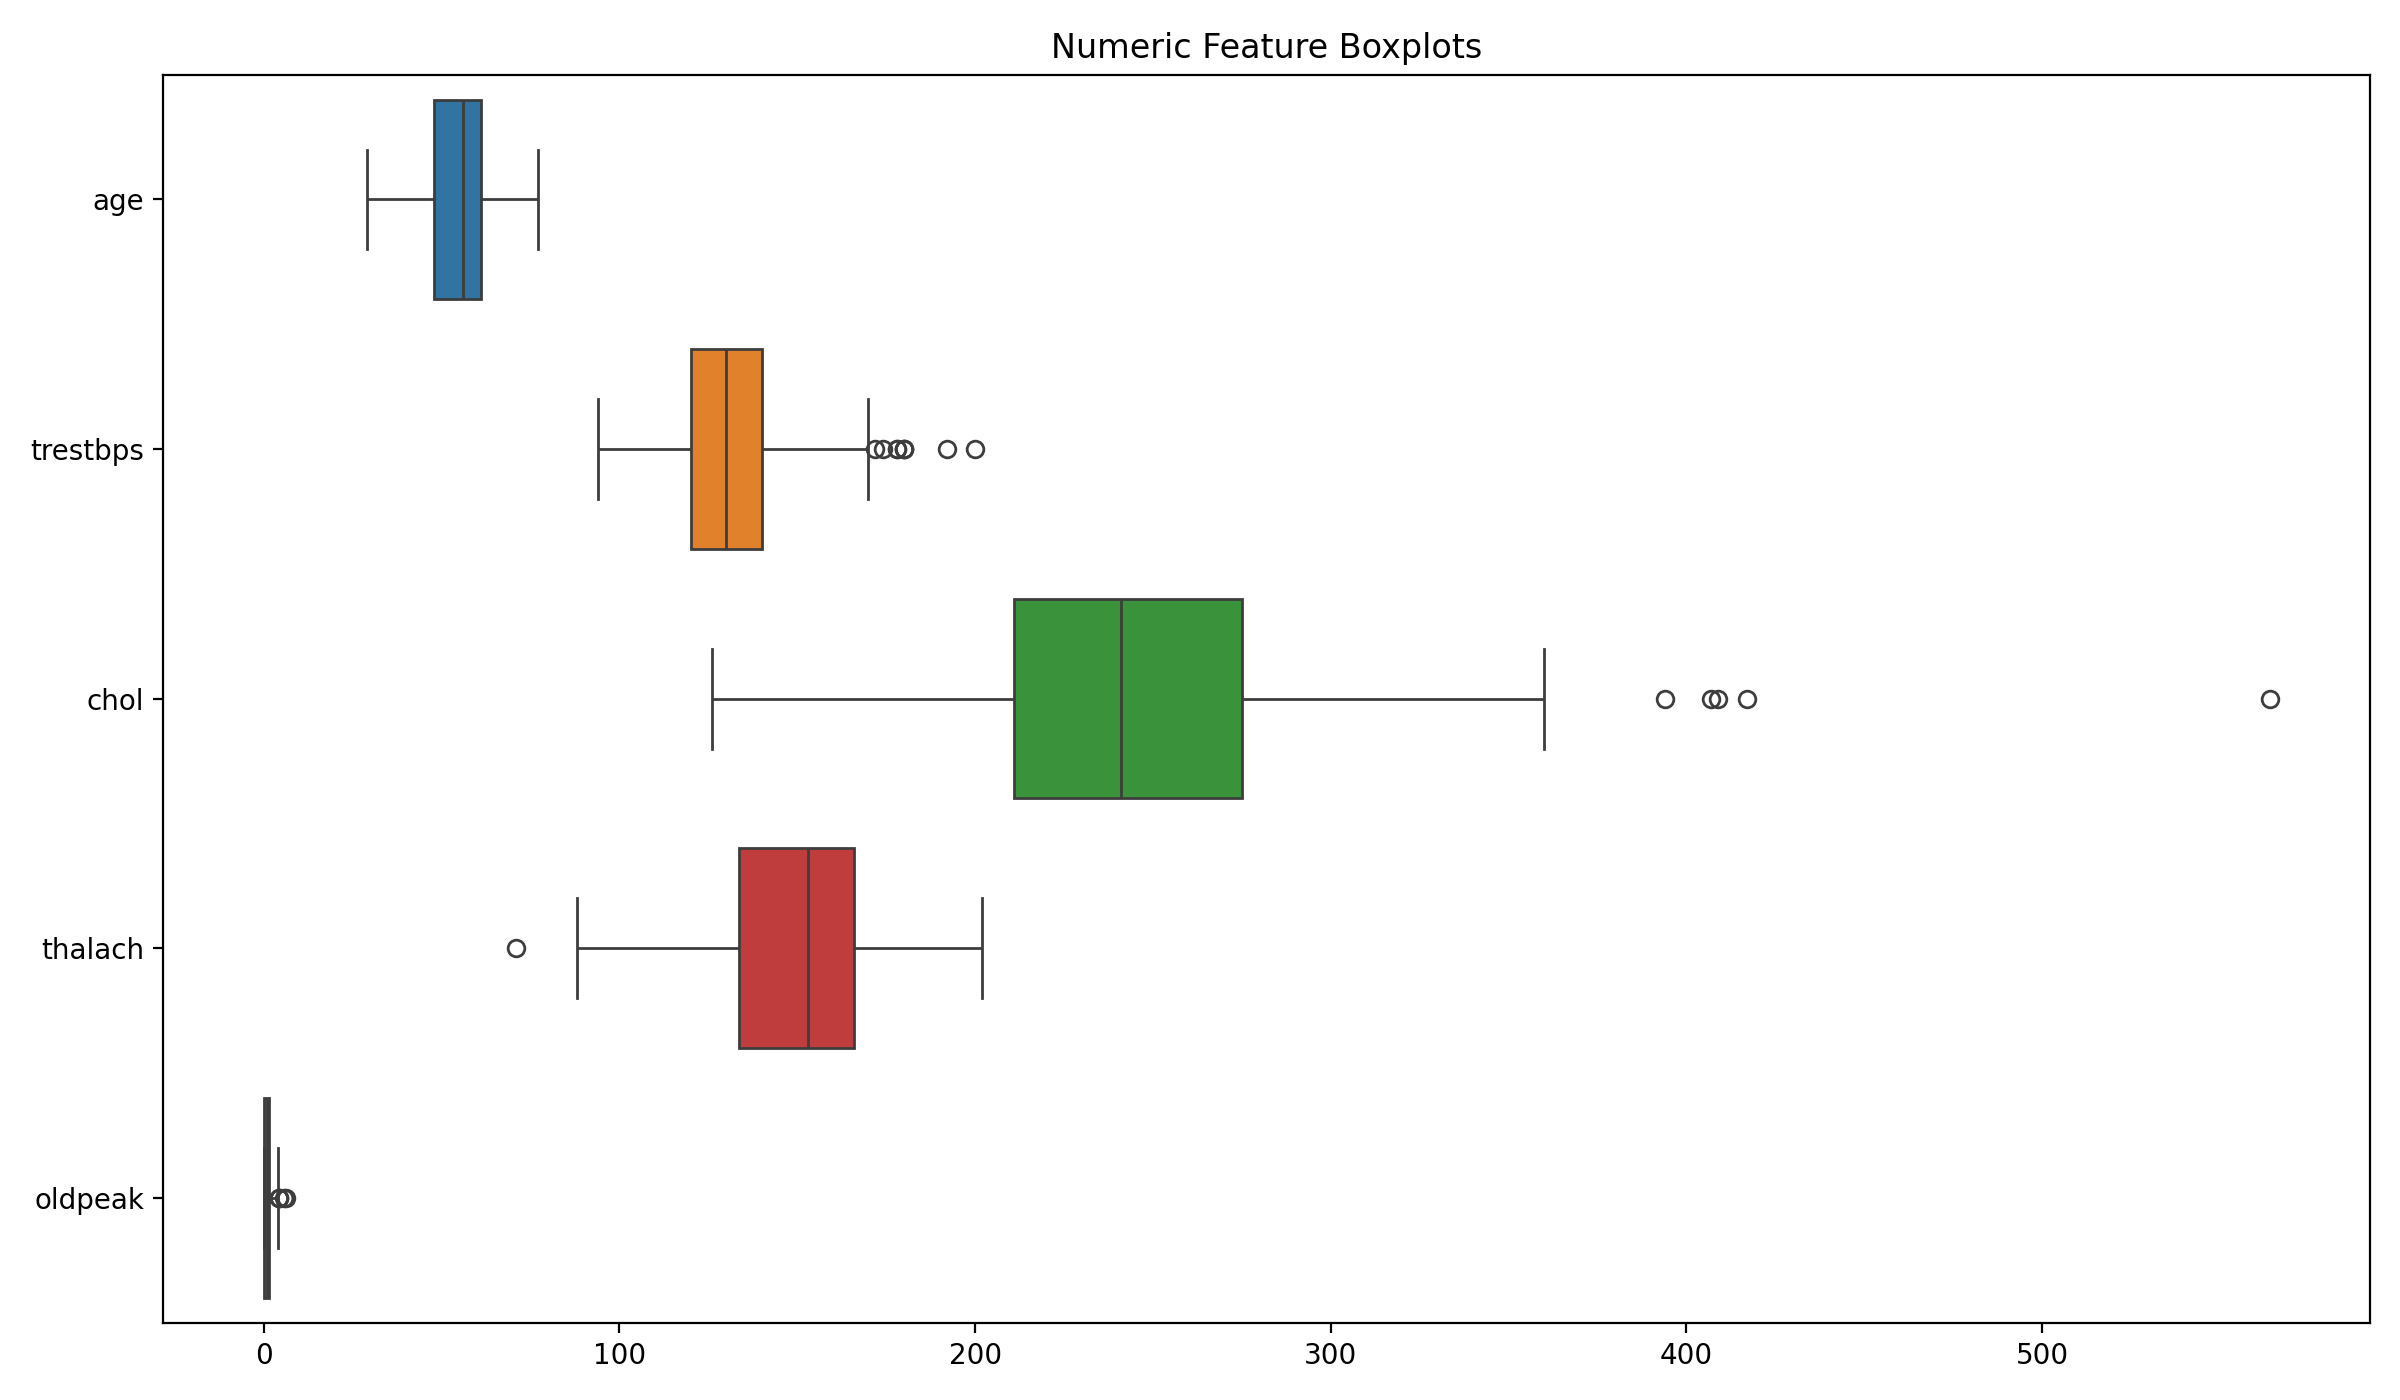

In [ ]:
# 1.4 Display EDA summary and visualizations generated by src/eda.py.
from IPython.display import display, Image

summary_path = PROJECT_ROOT / "artifacts" / "metrics" / "data_summary.json"
if summary_path.exists():
    eda_summary = json.loads(summary_path.read_text())
    print(json.dumps(eda_summary, indent=2))
else:
    print(f"Summary not found at {summary_path}. Check the EDA output above.")

plot_paths = [
    PROJECT_ROOT / "artifacts" / "plots" / "feature_histograms.png",
    PROJECT_ROOT / "artifacts" / "plots" / "correlation_heatmap.png",
    PROJECT_ROOT / "artifacts" / "plots" / "class_balance.png",
    PROJECT_ROOT / "artifacts" / "plots" / "boxplots_numeric.png",
]
for plot_path in plot_paths:
    if plot_path.exists():
        print(plot_path.name)
        display(Image(filename=str(plot_path)))
    else:
        print("Plot not found:", plot_path)

# Stage 2 — Feature preparation and model development

The training workflow builds a preprocessing pipeline for numeric and categorical inputs, compares logistic regression with a random forest model, performs parameter tuning with cross-validation, and records model quality using accuracy, precision, recall, and ROC-AUC metrics.

In [ ]:
# 2.1 Train/tune models and save metrics, plots, and the final reusable model.
result = subprocess.run(
    [sys.executable, "-m", "src.train"],
    cwd=PROJECT_ROOT,
    text=True,
    capture_output=True
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"Model training failed with exit code {result.returncode}")

              model  best_cv_roc_auc  test_accuracy  test_precision  test_recall  test_roc_auc                                                                                                                            best_params
logistic_regression         0.903140       0.885246        0.838710     0.928571       0.96645                                      {"classifier__C": 0.1, "classifier__class_weight": "balanced", "classifier__solver": "liblinear"}
      random_forest         0.899675       0.868852        0.833333     0.892857       0.94697 {"classifier__class_weight": null, "classifier__max_depth": null, "classifier__min_samples_split": 5, "classifier__n_estimators": 400}

Saved reproducible pipeline to: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/artifacts/model.joblib

2026/10/20 14:40:09 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model si

In [ ]:
#verify saved models
from pathlib import Path
import json
import pandas as pd
import joblib

print("Model exists:", Path("artifacts/model.joblib").exists())

metrics_file = Path("artifacts/metrics/final_metrics.json")
comparison_file = Path("artifacts/metrics/model_comparison.csv")

print("Final metrics file exists:", metrics_file.exists())
print("Model comparison file exists:", comparison_file.exists())

if comparison_file.exists():
    display(pd.read_csv(comparison_file))

if metrics_file.exists():
    print(json.dumps(json.loads(metrics_file.read_text()), indent=2))

model = joblib.load("artifacts/model.joblib")
print("\nReusable model loaded successfully:", type(model).__name__)

Model exists: True
Final metrics file exists: True
Model comparison file exists: True


,model,best_cv_roc_auc,test_accuracy,test_precision,test_recall,test_roc_auc,best_params
0,logistic_regression,0.903140,0.885246,0.838710,0.928571,0.96645,"{""classifier__C"": 0.1, ""classifier__class_weig..."
1,random_forest,0.899675,0.868852,0.833333,0.892857,0.94697,"{""classifier__class_weight"": null, ""classifier..."


{
  "selected_model": "logistic_regression",
  "selection_criterion": "best_cv_roc_auc (5-fold stratified CV on the training split)",
  "selection_note": "Model chosen on cross-validated ROC-AUC; the test set was not used for selection and is reported as the final held-out estimate.",
  "results": [
    {
      "model": "logistic_regression",
      "best_cv_roc_auc": 0.9031400966183576,
      "test_accuracy": 0.8852459016393442,
      "test_precision": 0.8387096774193549,
      "test_recall": 0.9285714285714286,
      "test_roc_auc": 0.9664502164502164,
      "best_params": "{\"classifier__C\": 0.1, \"classifier__class_weight\": \"balanced\", \"classifier__solver\": \"liblinear\"}"
    },
    {
      "model": "random_forest",
      "best_cv_roc_auc": 0.8996745605441256,
      "test_accuracy": 0.8688524590163934,
      "test_precision": 0.8333333333333334,
      "test_recall": 0.8928571428571429,
      "test_roc_auc": 0.946969696969697,
      "best_params": "{\"classifier__class_weight\

In [ ]:
# 2.2 Inspect model comparison and final evaluation metrics.
metrics_dir = PROJECT_ROOT / "artifacts" / "metrics"
comparison_path = metrics_dir / "model_comparison.csv"
final_metrics_path = metrics_dir / "final_metrics.json"

if comparison_path.exists():
    comparison_df = pd.read_csv(comparison_path)
    display(comparison_df)
else:
    print("Model comparison file not found:", comparison_path)

if final_metrics_path.exists():
    final_metrics = json.loads(final_metrics_path.read_text())
    print(json.dumps(final_metrics, indent=2))
else:
    print("Final metrics file not found:", final_metrics_path)

,model,best_cv_roc_auc,test_accuracy,test_precision,test_recall,test_roc_auc,best_params
0,logistic_regression,0.903140,0.885246,0.838710,0.928571,0.96645,"{""classifier__C"": 0.1, ""classifier__class_weig..."
1,random_forest,0.899675,0.868852,0.833333,0.892857,0.94697,"{""classifier__class_weight"": null, ""classifier..."


{
  "selected_model": "logistic_regression",
  "selection_criterion": "best_cv_roc_auc (5-fold stratified CV on the training split)",
  "selection_note": "Model chosen on cross-validated ROC-AUC; the test set was not used for selection and is reported as the final held-out estimate.",
  "results": [
    {
      "model": "logistic_regression",
      "best_cv_roc_auc": 0.9031400966183576,
      "test_accuracy": 0.8852459016393442,
      "test_precision": 0.8387096774193549,
      "test_recall": 0.9285714285714286,
      "test_roc_auc": 0.9664502164502164,
      "best_params": "{\"classifier__C\": 0.1, \"classifier__class_weight\": \"balanced\", \"classifier__solver\": \"liblinear\"}"
    },
    {
      "model": "random_forest",
      "best_cv_roc_auc": 0.8996745605441256,
      "test_accuracy": 0.8688524590163934,
      "test_precision": 0.8333333333333334,
      "test_recall": 0.8928571428571429,
      "test_roc_auc": 0.946969696969697,
      "best_params": "{\"classifier__class_weight\

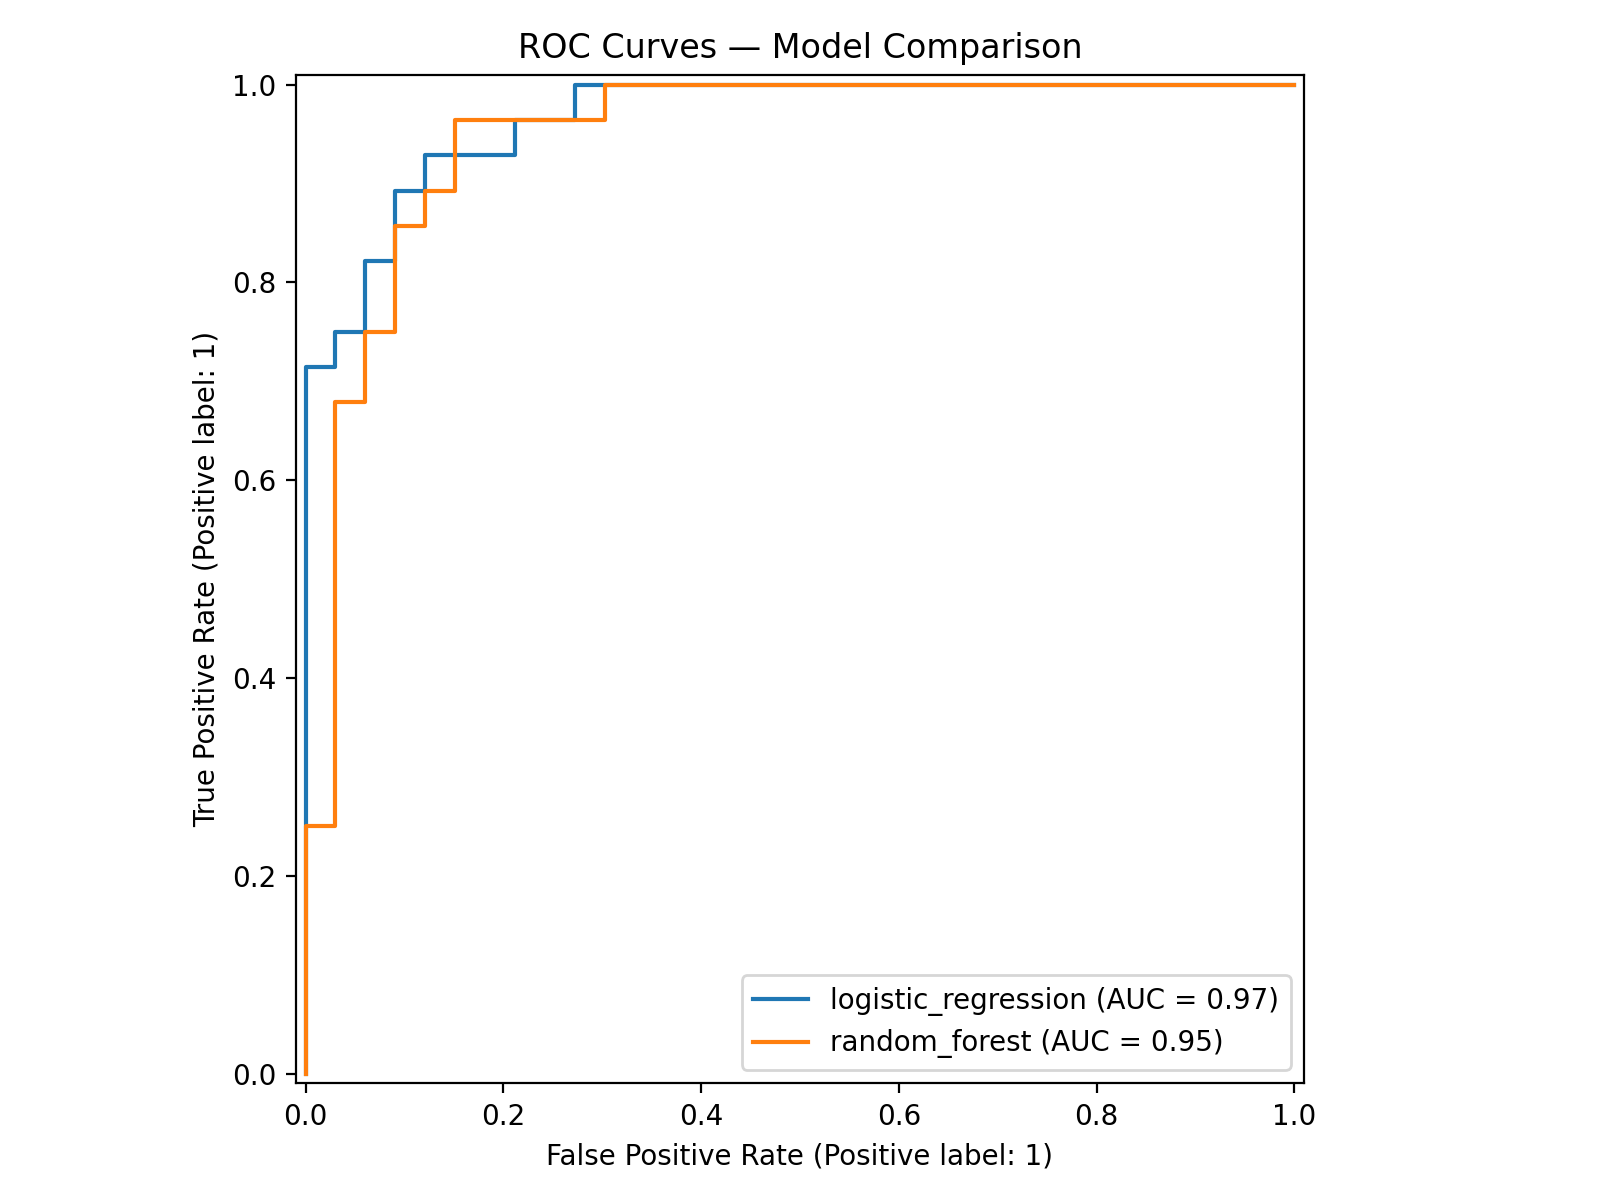

In [ ]:
# 2.3 Display the ROC curve plot generated by training.
roc_path = PROJECT_ROOT / "artifacts" / "plots" / "roc_curves.png"
if roc_path.exists():
    display(Image(filename=str(roc_path)))
else:
    print("ROC plot not found:", roc_path)

# Stage 3 — Experiment tracking and artifact management

The training process stores experiment values, evaluation metrics, generated plots, and model artifacts in the local MLflow tracking store so the workflow remains traceable and reproducible.

In [ ]:
# 3.1 Confirm the MLflow tracking store and list available run files.
mlruns_dir = PROJECT_ROOT / "mlruns"
print("MLflow tracking directory:", mlruns_dir)
print("Directory exists:", mlruns_dir.exists())
if mlruns_dir.exists():
    experiment_dirs = [p for p in mlruns_dir.iterdir() if p.is_dir()]
    print("Experiment folders:", [p.name for p in experiment_dirs])

MLflow tracking directory: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/mlruns
Directory exists: True
Experiment folders: ['0', 'models', '.trash', '391924175758160871']


In [ ]:
# 3.2 Summarize available MLflow runs programmatically.
import mlflow
from mlflow.tracking import MlflowClient

tracking_uri = f"file:{(PROJECT_ROOT / 'mlruns').resolve()}"
mlflow.set_tracking_uri(tracking_uri)
client = MlflowClient(tracking_uri=tracking_uri)
experiments = client.search_experiments()
print("Experiments found:", len(experiments))

run_rows = []
for exp in experiments:
    runs = client.search_runs([exp.experiment_id], max_results=100)
    for run in runs:
        run_rows.append({
            "experiment": exp.name,
            "run_id": run.info.run_id,
            "status": run.info.status,
            **{f"metric_{k}": v for k, v in run.data.metrics.items()},
        })
if run_rows:
    display(pd.DataFrame(run_rows))
else:
    print("No runs found yet. Run Task 2 successfully before reviewing MLflow.")

Experiments found: 2


,experiment,run_id,status,metric_test_precision,metric_test_roc_auc,metric_test_recall,metric_best_cv_roc_auc,metric_test_accuracy
0,Heart-Disease-MLOps-Assignment-01,9dc7a3d709a34d87ba6d8b664528b7d1,FINISHED,0.833333,0.94697,0.892857,0.899675,0.868852
1,Heart-Disease-MLOps-Assignment-01,2553886644ed40149703d3bf441f67f5,FINISHED,0.838710,0.96645,0.928571,0.903140,0.885246
2,Heart-Disease-MLOps-Assignment-01,481eeaf6b9ee4e8a9b376397e55930b6,FINISHED,NaN,NaN,NaN,NaN,NaN
3,Heart-Disease-MLOps-Assignment-01,b8df9f03b95c42ca9ae517ad54fbbc7f,FINISHED,0.833333,0.94697,0.892857,0.899675,0.868852
4,Heart-Disease-MLOps-Assignment-01,cf6cfeadb9cb4a3a897fc376b3cb765f,FINISHED,0.838710,0.96645,0.928571,0.903140,0.885246
5,Heart-Disease-MLOps-Assignment-01,89ade91f27ef4b158870b9e016468d18,FINISHED,NaN,NaN,NaN,NaN,NaN
6,Heart-Disease-MLOps-Assignment-01,c95866e27f6c42e294468dd7f82c21e5,FINISHED,0.833333,0.94697,0.892857,0.899675,0.868852
7,Heart-Disease-MLOps-Assignment-01,0055d16d22794851b600e9cc4d051ba5,FINISHED,0.838710,0.96645,0.928571,0.903140,0.885246
8,Heart-Disease-MLOps-Assignment-01,f0583e43a8dd42429bbd10521821bb76,FINISHED,NaN,NaN,NaN,NaN,NaN
9,Heart-Disease-MLOps-Assignment-01,4d4c419c75914accb73d9469694a8996,FINISHED,0.833333,0.94697,0.892857,0.899675,0.868852


In [ ]:
from mlflow.tracking import MlflowClient
import pandas as pd

client = MlflowClient()

for exp in client.search_experiments():
    print(f"\nExperiment: {exp.name}")

    for run in client.search_runs([exp.experiment_id], max_results=100):
        print("\nRun ID:", run.info.run_id)
        print("Status:", run.info.status)
        print("Start time:", pd.to_datetime(run.info.start_time, unit="ms"))
        print("End time:", pd.to_datetime(run.info.end_time, unit="ms"))
        print("Parameters:", run.data.params)
        print("Metrics:", run.data.metrics)
        print("Tags:", run.data.tags)


Experiment: Heart-Disease-MLOps-Assignment-01

Run ID: 9dc7a3d709a34d87ba6d8b664528b7d1
Status: FINISHED
Start time: 2026-10-20 09:10:09.740000
End time: 2026-10-20 09:10:18.750000
Parameters: {'best_params': '{"classifier__class_weight": null, "classifier__max_depth": null, "classifier__min_samples_split": 5, "classifier__n_estimators": 400}', 'model': 'random_forest', 'cv_scoring': 'roc_auc'}
Metrics: {'test_precision': 0.8333333333333334, 'test_roc_auc': 0.946969696969697, 'test_recall': 0.8928571428571429, 'best_cv_roc_auc': 0.8996745605441256, 'test_accuracy': 0.8688524590163934}
Tags: {'mlflow.parentRunId': '481eeaf6b9ee4e8a9b376397e55930b6', 'mlflow.user': 'kavyakollipara', 'mlflow.source.git.commit': '86ade26159b0dfdd860be4f78b44f0f0654e8c22', 'mlflow.runName': 'random_forest', 'mlflow.source.name': '/Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/src/train.py', 'mlflow.log-model.history': '[{"run_id": "9dc7a3d709a34d87ba6d8b664528b7d1", "artifact_path": "ran

To inspect the interactive MLflow UI, run the following in a separate terminal from the project root (or use the notebook cell below if you want it to run as a background process). The UI is normally available at `http://127.0.0.1:5000`. Do not launch multiple servers on the same port.

In [ ]:
import subprocess
import sys
import time
import webbrowser
from pathlib import Path

project_root = Path.cwd()
tracking_dir = project_root / "mlruns"
log_file = project_root / "mlflow_ui.log"

log_handle = open(log_file, "a")

mlflow_process = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "ui",
        "--backend-store-uri", f"file:{tracking_dir.resolve()}",
        "--host", "127.0.0.1",
        "--port", "5001"
    ],
    cwd=str(project_root),
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

time.sleep(3)

if mlflow_process.poll() is None:
    print("MLflow process started.")
    print("Open: http://127.0.0.1:5001")
    webbrowser.open("http://127.0.0.1:5001")
else:
    log_handle.close()
    print("MLflow failed to start. Error log:")
    print(log_file.read_text()[-3000:])

MLflow process started.
Open: http://127.0.0.1:5001


# Task 4 — Model Packaging and Reproducibility 

The training script saves the fitted preprocessing + estimator pipeline as `artifacts/model.joblib`. The project's `requirements.txt` records dependencies.

In [ ]:
# 4.1 Verify the packaged model and dependency manifest.
model_path = PROJECT_ROOT / "artifacts" / "model.joblib"
requirements_path = PROJECT_ROOT / "requirements.txt"
print("Model exists:", model_path.exists(), model_path)
print("Requirements exists:", requirements_path.exists(), requirements_path)
if requirements_path.exists():
    print("\n--- requirements.txt ---")
    print(requirements_path.read_text())

Model exists: True /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/artifacts/model.joblib
Requirements exists: True /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/requirements.txt

--- requirements.txt ---
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.5.2
matplotlib==3.9.2
seaborn==0.13.2
mlflow==2.17.2
joblib==1.4.2
ucimlrepo==0.0.7
fastapi==0.115.5
uvicorn[standard]==0.32.1
prometheus-fastapi-instrumentator==7.0.0
pydantic==2.10.3



In [ ]:
# 4.2 Load the packaged model and run one sample prediction.
# Uses a representative sample with the 13 input fields expected by the API.
from src.config import NUMERIC_FEATURES, CATEGORICAL_FEATURES
import pandas as pd
import joblib

if not model_path.exists():
    raise FileNotFoundError("Model not found. Run Task 2 training first.")

model = joblib.load(model_path)
sample = {
    "age": 57, "sex": 1, "cp": 2, "trestbps": 130, "chol": 236,
    "fbs": 0, "restecg": 0, "thalach": 174, "exang": 0,
    "oldpeak": 0.0, "slope": 1, "ca": 0, "thal": 2
}
sample_df = pd.DataFrame([sample])
pred = int(model.predict(sample_df)[0])
proba = model.predict_proba(sample_df)[0]
print("Predicted class:", pred, "(1 = heart disease present; 0 = absent)")
print("Class probabilities:", {str(i): float(p) for i, p in enumerate(proba)})

Predicted class: 0 (1 = heart disease present; 0 = absent)
Class probabilities: {'0': 0.8164219915351035, '1': 0.1835780084648965}


In [ ]:
from pathlib import Path
import joblib

model_path = PROJECT_ROOT / "artifacts" / "model.joblib"
requirements_path = PROJECT_ROOT / "requirements.txt"

print("1. REUSABLE MODEL")
print("Exists:", model_path.exists())

if model_path.exists():
    model = joblib.load(model_path)
    print("Type:", type(model).__name__)

    if hasattr(model, "steps"):
        print("\nPipeline steps:")
        for name, step in model.steps:
            print(f"  {name}: {type(step).__name__}")

        print("\nPreprocessing configuration:")
        for name, step in model.steps:
            if hasattr(step, "transformers"):
                for transformer_name, transformer, columns in step.transformers:
                    print(
                        f"  {transformer_name}: "
                        f"{type(transformer).__name__}, columns={columns}"
                    )

print("\n2. REQUIREMENTS")
print("Exists:", requirements_path.exists())
if requirements_path.exists():
    print(requirements_path.read_text())

1. REUSABLE MODEL
Exists: True
Type: Pipeline

Pipeline steps:
  preprocessor: ColumnTransformer
  classifier: LogisticRegression

Preprocessing configuration:
  numeric: Pipeline, columns=['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
  categorical: Pipeline, columns=['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

2. REQUIREMENTS
Exists: True
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.5.2
matplotlib==3.9.2
seaborn==0.13.2
mlflow==2.17.2
joblib==1.4.2
ucimlrepo==0.0.7
fastapi==0.115.5
uvicorn[standard]==0.32.1
prometheus-fastapi-instrumentator==7.0.0
pydantic==2.10.3



In [ ]:
from sklearn.pipeline import Pipeline

for name, transformer, columns in model.named_steps["preprocessor"].transformers_:
    print(f"\n{name.upper()} — columns: {list(columns)}")

    if isinstance(transformer, Pipeline):
        for step_name, step in transformer.steps:
            print(f"  {step_name}: {type(step).__name__}")


NUMERIC — columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
  imputer: SimpleImputer
  scaler: StandardScaler

CATEGORICAL — columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
  imputer: SimpleImputer
  onehot: OneHotEncoder


# Task 5 — Automated Testing and CI/CD 

The project includes pytest unit tests and a GitHub Actions workflow. The workflow is stored in `.github/workflows/ci.yml`; GitHub executes it when the repository is pushed according to the configured triggers.

In [ ]:
from pathlib import Path
import sys
import subprocess

PROJECT_ROOT = Path.cwd().resolve()

# If the notebook is running in a subfolder, search parent folders.
for folder in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (
        (folder / "requirements.txt").exists()
        and (folder / "src").is_dir()
        and (folder / ".github" / "workflows" / "ci.yml").exists()
    ):
        PROJECT_ROOT = folder
        break

print("Project folder:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Workflow exists:", (PROJECT_ROOT / ".github/workflows/ci.yml").exists())
print("Source folder exists:", (PROJECT_ROOT / "src").is_dir())
print("Tests folder exists:", (PROJECT_ROOT / "tests").is_dir())

Project folder: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease
Python: 3.11.9
Workflow exists: True
Source folder exists: True
Tests folder exists: True


In [ ]:
result = subprocess.run(
    [sys.executable, "-m", "ruff", "--version"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False
)

print(result.stdout or result.stderr)

if result.returncode != 0:
    print("Install Ruff in the active notebook environment:")
    %pip install ruff

ruff 0.17.1



In [ ]:
from pathlib import Path

train_path = PROJECT_ROOT / "src" / "train.py"
train_text = train_path.read_text()

old_line = 'with mlflow.start_run(run_name="assignment_01_model_comparison") as parent_run:'
new_line = 'with mlflow.start_run(run_name="assignment_01_model_comparison"):'

if old_line not in train_text:
    print("The exact line was not found. No changes made.")
else:
    train_path.write_text(train_text.replace(old_line, new_line, 1))
    print("Fixed unused parent_run variable in src/train.py")

The exact line was not found. No changes made.


In [ ]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable, "-m", "ruff", "check",
        "src", "tests", "download_data.py"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False
)

print(result.stdout or "No Ruff errors found.")
if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

All checks passed!

Exit code: 0


In [ ]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

.....                                                                    [100%]
=============================== warnings summary ===============================
.venv/lib/python3.11/site-packages/starlette/testclient.py:40
  /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/.venv/lib/python3.11/site-packages/starlette/testclient.py:40: DeprecationWarning: The anyio.abc.BlockingPortal alias is deprecated, use anyio.from_thread.BlockingPortal instead.
    _PortalFactoryType = typing.Callable[[], typing.ContextManager[anyio.abc.BlockingPortal]]

src/api.py:48
  /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/src/api.py:48: DeprecationWarning: 
          on_event is deprecated, use lifespan event handlers instead.
  
          Read more about it in the
          [FastAPI docs for Lifespan Events](https://fastapi.tiangolo.com/advanced/events/).
          
    @app.on_event("startup")

.venv/lib/python3.11/site-packages/fastapi/applications.py:4495
  /Users/

In [ ]:

from pathlib import Path

workflow_path = PROJECT_ROOT / ".github" / "workflows" / "ci.yml"
workflow_text = workflow_path.read_text()

print("Current Ruff command:")
for line in workflow_text.splitlines():
    if "ruff check" in line:
        print(repr(line))



Current Ruff command:
'        run: ruff check src tests download_data.py'


In [ ]:

old_command = "ruff check ."
new_command = "ruff check src tests download_data.py"

if old_command not in workflow_text:
    print("No exact match found. Please share the Ruff command printed above.")
else:
    workflow_path.write_text(workflow_text.replace(old_command, new_command, 1))
    print("Updated successfully.")
    print("\n".join(
        line for line in workflow_path.read_text().splitlines()
        if "ruff check" in line
    ))


No exact match found. Please share the Ruff command printed above.


#
The GitHub Actions workflow completed successfully on the `main` branch.

![GitHub Actions CI/CD Success](screenshots/github_act1.png)

*Figure: Successful execution of the quality-test-train workflow.*

![GitHub Actions CI/CD Success](screenshots/github_act2.png)

*Figure: Successful execution of the quality-test-train workflow.*

![GitHub Actions CI/CD Success](screenshots/github_act3.png)

*Figure: Successful execution of the quality-test-train workflow.*

# Task 6 — Model Containerization

The project includes a `Dockerfile`, a FastAPI serving API, and a sample request. The API exposes `/health`, `/metadata`, `/predict`, and `/metrics`.

In [ ]:
#checking whether docker is active and running
DOCKER = "/Applications/Docker.app/Contents/Resources/bin/docker"

result = subprocess.run(
    [DOCKER, "info"],
    capture_output=True,
    text=True,
    check=False
)

print("Exit code:", result.returncode)
print((result.stdout or "")[-1500:])
if result.returncode != 0:
    print(result.stderr[-1500:])


Exit code: 0
  v1.26.0
    Path:     /Users/kavyakollipara/.docker/cli-plugins/docker-scout

Server:
 Containers: 2
  Running: 2
  Paused: 0
  Stopped: 0
 Images: 4
 Server Version: 29.8.2
 Storage Driver: overlayfs
  driver-type: io.containerd.snapshotter.v1
 Logging Driver: local
 Cgroup Driver: cgroupfs
 Cgroup Version: 2
 Plugins:
  Volume: local
  Network: bridge host ipvlan macvlan null overlay
  Log: awslogs fluentd gcplogs gelf journald json-file local splunk syslog
 CDI spec directories:
  /etc/cdi
  /var/run/cdi
 Discovered Devices:
  cdi: docker.com/gpu=webgpu
 Swarm: inactive
 Runtimes: io.containerd.runc.v2 runc
 Default Runtime: runc
 Init Binary: docker-init
 containerd version: ee2735368117d2eb259779949d5e75cdafec9761
 runc version: v1.5.1-0-g8f2685a4
 init version: de40ad0
 Security Options:
  seccomp
   Profile: builtin
  cgroupns
 Kernel Version: 7.0.14-linuxkit
 Operating System: Docker Desktop
 OSType: linux
 Architecture: aarch64
 CPUs: 8
 Total Memory: 3.825GiB
 

In [ ]:

assert (PROJECT_ROOT / "artifacts/model.joblib").exists(), (
    "Model missing. Run model training before building Docker."
)

result = subprocess.run(
    [
        DOCKER, "build",
        "-t", "heart-disease-mlops:latest",
        "."
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False
)

print((result.stdout or "")[-4000:])
if result.returncode != 0:
    print((result.stderr or "")[-4000:])

print("Docker build exit code:", result.returncode)



Docker build exit code: 0


In [ ]:
#remove any previous container
old = subprocess.run(
    [DOCKER, "rm", "-f", "heart-api-local"],
    capture_output=True,
    text=True,
    check=False
)

print(old.stdout or "No previous container needed removal.")

result = subprocess.run(
    [
        DOCKER, "run", "-d",
        "--name", "heart-api-local",
        "-p", "8000:8000",
        "heart-disease-mlops:latest"
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False
)

print("Exit code:", result.returncode)
print("Container ID:", result.stdout.strip())
if result.returncode != 0:
    print(result.stderr)


heart-api-local

Exit code: 0
Container ID: 1ef6d9aed5b14fcf0e1c7b9a69a5452069448b35f3129023c52ab1d1f9836c7c


In [ ]:
#Test the health endpoint
import requests

health_url = "http://127.0.0.1:8000/health"

for attempt in range(15):
    try:
        response = requests.get(health_url, timeout=3)
        print("HTTP status:", response.status_code)
        print("Response:", response.json())
        break
    except requests.RequestException:
        time.sleep(2)
else:
    print("API did not become available. Check the container logs.")


HTTP status: 200
Response: {'status': 'ok', 'model_loaded': True}


In [ ]:
#sending sample JSON to predict
import json
import requests
from pathlib import Path

sample_path = PROJECT_ROOT / "sample_request.json"

assert sample_path.exists(), f"Sample file not found: {sample_path}"

sample_payload = json.loads(sample_path.read_text())

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=sample_payload,
    timeout=10
)

print("HTTP status:", response.status_code)
print(json.dumps(response.json(), indent=2))

assert response.status_code == 200, response.text

result = response.json()
assert "prediction" in result, "Prediction field missing"
assert "confidence" in result, "Confidence field missing"

print("\nPASS: Docker API returned prediction and confidence.")


HTTP status: 200
{
  "prediction": 0,
  "confidence": 0.6224429317604675,
  "probability_absence": 0.6224429317604675,
  "probability_presence": 0.3775570682395325
}

PASS: Docker API returned prediction and confidence.


In [ ]:
result = subprocess.run(
    [DOCKER, "ps", "--filter", "name=heart-api-local"],
    capture_output=True,
    text=True
)
print(result.stdout)

CONTAINER ID   IMAGE                        COMMAND                  CREATED         STATUS         PORTS                                         NAMES
1ef6d9aed5b1   heart-disease-mlops:latest   "uvicorn src.api:app…"   4 seconds ago   Up 4 seconds   0.0.0.0:8000->8000/tcp, [::]:8000->8000/tcp   heart-api-local



### Docker Desktop — Running Container

Docker Desktop confirms that the Heart Disease API container is running and port 8000 is exposed for local access.

![Docker Desktop showing the running Heart Disease API container](screenshots/docker_desktop.png)

*Figure: Docker Desktop showing the heart-api-local container running on port 8000.*

In [ ]:
#container logs
import requests
import subprocess

for endpoint in ["/health", "/metadata", "/metrics"]:
    response = requests.get(
        f"http://127.0.0.1:8000{endpoint}",
        timeout=10
    )
    print(f"\n{endpoint}: HTTP {response.status_code}")
    print(response.text[:500])

result = subprocess.run(
    [DOCKER, "logs", "--tail", "50", "heart-api-local"],
    capture_output=True,
    text=True,
    check=False
)

print("\n--- Container logs ---")
print(result.stdout)
if result.stderr:
    print(result.stderr)



/health: HTTP 200
{"status":"ok","model_loaded":true}

/metadata: HTTP 200
{"features":["age","trestbps","chol","thalach","oldpeak","sex","cp","fbs","restecg","exang","slope","ca","thal"],"target":"0 = absence, 1 = presence","model_artifact":"/app/artifacts/model.joblib"}

/metrics: HTTP 200
# HELP python_gc_objects_collected_total Objects collected during gc
# TYPE python_gc_objects_collected_total counter
python_gc_objects_collected_total{generation="0"} 2876.0
python_gc_objects_collected_total{generation="1"} 2756.0
python_gc_objects_collected_total{generation="2"} 393.0
# HELP python_gc_objects_uncollectable_total Uncollectable objects found during GC
# TYPE python_gc_objects_uncollectable_total counter
python_gc_objects_uncollectable_total{generation="0"} 0.0
python_gc_objects_

--- Container logs ---
INFO:     192.168.65.1:64003 - "GET /health HTTP/1.1" 200 OK
INFO:     192.168.65.1:55765 - "POST /predict HTTP/1.1" 200 OK
INFO:     192.168.65.1:58923 - "GET /health HTTP/1.1" 200

# Task 7 — Production Deployment with Kubernetes

The project provides Kubernetes manifests under `k8s/`. For local deployment, Docker Desktop Kubernetes or Minikube must be installed and running. A `LoadBalancer` service on a local cluster may require platform-specific access instructions.

In [ ]:
import subprocess
import json
from pathlib import Path
from datetime import datetime, timezone

PROJECT_ROOT = Path.cwd()

def run_command(command):
    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=30
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr or result.stdout)
    return result.stdout.strip()

service_json = run_command([
    "kubectl", "get", "service", "heart-api",
    "-n", "heart-mlops", "-o", "json"
])

service = json.loads(service_json)

service_type = service["spec"]["type"]
external_ips = [
    item.get("ip")
    for item in service.get("status", {})
                       .get("loadBalancer", {})
                       .get("ingress", [])
    if item.get("ip")
]
service_ports = service["spec"]["ports"]

print("Service:", service["metadata"]["name"])
print("Namespace:", service["metadata"]["namespace"])
print("Type:", service_type)
print("External IP:", external_ips)
print("Ports:", service_ports)

assert service_type == "LoadBalancer", (
    f"Expected LoadBalancer, found {service_type}"
)
assert external_ips, "No LoadBalancer IP assigned. Check minikube tunnel."

print("\nLoadBalancer configuration verified.")

Service: heart-api
Namespace: heart-mlops
Type: LoadBalancer
External IP: ['127.0.0.1']
Ports: [{'nodePort': 30120, 'port': 80, 'protocol': 'TCP', 'targetPort': 8000}]

LoadBalancer configuration verified.


In [ ]:
import urllib.request
import urllib.error

API_BASE_URL = "http://127.0.0.1"

def check_endpoint(path):
    url = f"{API_BASE_URL}{path}"

    try:
        with urllib.request.urlopen(url, timeout=10) as response:
            body = response.read().decode("utf-8", errors="replace")

            print(f"Endpoint: {url}")
            print(f"HTTP status: {response.status}")
            print(f"Content type: {response.headers.get('Content-Type')}")
            print(f"Response preview: {body[:250]}")
            print("-" * 50)

            return response.status, body

    except Exception as exc:
        print(f"Request failed for {url}: {exc}")
        raise

docs_status, docs_body = check_endpoint("/docs")
assert docs_status == 200, "Swagger documentation check failed."

openapi_status, openapi_body = check_endpoint("/openapi.json")
assert openapi_status == 200, "OpenAPI schema check failed."

openapi_schema = json.loads(openapi_body)

print("API documentation and OpenAPI schema checks passed.")

Endpoint: http://127.0.0.1/docs
HTTP status: 200
Content type: text/html; charset=utf-8
Response preview: 
    <!DOCTYPE html>
    <html>
    <head>
    <link type="text/css" rel="stylesheet" href="https://cdn.jsdelivr.net/npm/swagger-ui-dist@5/swagger-ui.css">
    <link rel="shortcut icon" href="https://fastapi.tiangolo.com/img/favicon.png">
    <title>
--------------------------------------------------
Endpoint: http://127.0.0.1/openapi.json
HTTP status: 200
Content type: application/json
Response preview: {"openapi":"3.1.0","info":{"title":"Heart Disease Prediction API","description":"MLOps Assignment 01 prediction service.","version":"1.0.0"},"paths":{"/health":{"get":{"summary":"Health","operationId":"health_health_get","responses":{"200":{"descript
--------------------------------------------------
API documentation and OpenAPI schema checks passed.


![FASTAPI SCREENSHOT](screenshots/FastAPI1.png)|

![FASTAPI SCREENSHOT](screenshots/FastAPI2.png)

*FIGURE: TEST RUN FROM API*

In [ ]:
paths = openapi_schema.get("paths", {})

for path, methods in paths.items():
    for method, details in methods.items():
        if method.lower() in {"get", "post", "put", "delete"}:
            print(
                method.upper(),
                path,
                "-",
                details.get("summary", "No summary")
            )

predict_operation = paths.get("/predict", {}).get("post")

if predict_operation:
    print("\nPrediction endpoint found.")

    request_body = predict_operation.get("requestBody", {})
    content = request_body.get("content", {})

    for content_type, details in content.items():
        schema = details.get("schema", {})
        print("Content type:", content_type)
        print("Request schema:", json.dumps(schema, indent=2))

        if "$ref" in schema:
            schema_name = schema["$ref"].split("/")[-1]
            print(
                "Referenced schema:",
                json.dumps(
                    openapi_schema.get("components", {})
                                  .get("schemas", {})
                                  .get(schema_name, {}),
                    indent=2
                )
            )
else:
    print("No POST /predict endpoint found.")

GET /health - Health
GET /metadata - Metadata
POST /predict - Predict
GET /metrics - Metrics

Prediction endpoint found.
Content type: application/json
Request schema: {
  "$ref": "#/components/schemas/HeartDiseaseRequest"
}
Referenced schema: {
  "properties": {
    "age": {
      "type": "number",
      "maximum": 120.0,
      "minimum": 1.0,
      "title": "Age"
    },
    "sex": {
      "type": "integer",
      "maximum": 1.0,
      "minimum": 0.0,
      "title": "Sex"
    },
    "cp": {
      "type": "integer",
      "maximum": 3.0,
      "minimum": 0.0,
      "title": "Cp"
    },
    "trestbps": {
      "type": "number",
      "minimum": 0.0,
      "title": "Trestbps"
    },
    "chol": {
      "type": "number",
      "minimum": 0.0,
      "title": "Chol"
    },
    "fbs": {
      "type": "integer",
      "maximum": 1.0,
      "minimum": 0.0,
      "title": "Fbs"
    },
    "restecg": {
      "type": "integer",
      "maximum": 2.0,
      "minimum": 0.0,
      "title": "Restecg"


In [ ]:
verification_results = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "deployment": {
        "service": service["metadata"]["name"],
        "namespace": service["metadata"]["namespace"],
        "type": service_type,
        "external_ips": external_ips,
        "ports": service_ports,
    },
    "tests": {
        "docs_http_status": docs_status,
        "openapi_http_status": openapi_status,
        "loadbalancer_configured": service_type == "LoadBalancer",
    },
}

artifact_dir = PROJECT_ROOT / "artifacts" / "deployment"
artifact_dir.mkdir(parents=True, exist_ok=True)

report_file = artifact_dir / "loadbalancer_verification.json"
report_file.write_text(
    json.dumps(verification_results, indent=2),
    encoding="utf-8"
)

print("Verification report saved to:", report_file)
print(json.dumps(verification_results, indent=2))

Verification report saved to: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/artifacts/deployment/loadbalancer_verification.json
{
  "timestamp_utc": "2026-10-20T09:10:36.099820+00:00",
  "deployment": {
    "service": "heart-api",
    "namespace": "heart-mlops",
    "type": "LoadBalancer",
    "external_ips": [
      "127.0.0.1"
    ],
    "ports": [
      {
        "nodePort": 30120,
        "port": 80,
        "protocol": "TCP",
        "targetPort": 8000
      }
    ]
  },
  "tests": {
    "docs_http_status": 200,
    "openapi_http_status": 200,
    "loadbalancer_configured": true
  }
}


In [ ]:
import subprocess
import json
import urllib.request

service_json = subprocess.run(
    [
        "kubectl", "get", "svc", "heart-api",
        "-n", "heart-mlops", "-o", "json"
    ],
    capture_output=True,
    text=True,
    check=True
).stdout

service = json.loads(service_json)

assert service["spec"]["type"] == "LoadBalancer"

external_ip = service["status"]["loadBalancer"]["ingress"][0]["ip"]
service_port = service["spec"]["ports"][0]["port"]

API_BASE_URL = f"http://{external_ip}:{service_port}"

print("LoadBalancer URL:", API_BASE_URL)

with urllib.request.urlopen(
    f"{API_BASE_URL}/docs",
    timeout=10
) as response:
    print("Swagger HTTP status:", response.status)
    assert response.status == 200

LoadBalancer URL: http://127.0.0.1:80
Swagger HTTP status: 200


In [ ]:
import json
from IPython.display import display, Markdown

predict_operation = openapi_schema.get("paths", {}).get("/predict", {}).get("post")

if predict_operation:
    print("Prediction endpoint found.")
    print(json.dumps(predict_operation, indent=2))
else:
    print("POST /predict was not found. Check the OpenAPI paths.")

Prediction endpoint found.
{
  "summary": "Predict",
  "operationId": "predict_predict_post",
  "requestBody": {
    "content": {
      "application/json": {
        "schema": {
          "$ref": "#/components/schemas/HeartDiseaseRequest"
        }
      }
    },
    "required": true
  },
  "responses": {
    "200": {
      "description": "Successful Response",
      "content": {
        "application/json": {
          "schema": {
            "$ref": "#/components/schemas/PredictionResponse"
          }
        }
      }
    },
    "422": {
      "description": "Validation Error",
      "content": {
        "application/json": {
          "schema": {
            "$ref": "#/components/schemas/HTTPValidationError"
          }
        }
      }
    }
  }
}


In [ ]:
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd()

matches = [
    path for path in PROJECT_ROOT.rglob("*")
    if path.is_file() and path.name.lower() == "sample_request.json"
    and not any(
        part in {".venv", "venv", ".git", "node_modules"}
        for part in path.parts
    )
]

if not matches:
    raise FileNotFoundError(
        "sample_request.JSON not found. Check PROJECT_ROOT."
    )

sample_file = matches[0]

with open(sample_file, "r", encoding="utf-8") as f:
    prediction_payload = json.load(f)

print("Loaded from:", sample_file)
print(json.dumps(prediction_payload, indent=2))

Loaded from: /Users/kavyakollipara/Downloads/mlops_assignment_01_heart_disease/sample_request.json
{
  "age": 63,
  "sex": 1,
  "cp": 3,
  "trestbps": 145,
  "chol": 233,
  "fbs": 1,
  "restecg": 0,
  "thalach": 150,
  "exang": 0,
  "oldpeak": 2.3,
  "slope": 0,
  "ca": 0,
  "thal": 1
}


In [ ]:
import urllib.request
import urllib.error

API_BASE_URL = "http://127.0.0.1"

request = urllib.request.Request(
    url=f"{API_BASE_URL}/predict",
    data=json.dumps(prediction_payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

try:
    with urllib.request.urlopen(request, timeout=15) as response:
        result = json.loads(response.read().decode("utf-8"))
        print("HTTP Status:", response.status)
        print("API Response:")
        print(json.dumps(result, indent=2))

except urllib.error.HTTPError as e:
    print("HTTP Error:", e.code)
    print(e.read().decode("utf-8"))

except Exception as e:
    print("Request failed:", repr(e))

HTTP Status: 200
API Response:
{
  "prediction": 0,
  "confidence": 0.6224429317604675,
  "probability_absence": 0.6224429317604675,
  "probability_presence": 0.3775570682395325
}


In [ ]:
import subprocess
import json

result = subprocess.run(
    ["kubectl", "get", "service", "heart-api", "-n", "heart-mlops", "-o", "json"],
    capture_output=True,
    text=True,
    check=True
)

service = json.loads(result.stdout)

print("Service type:", service["spec"]["type"])
print("External IP:", service["status"]["loadBalancer"]["ingress"])
print("Port mapping:", service["spec"]["ports"])

Service type: LoadBalancer
External IP: [{'ip': '127.0.0.1', 'ipMode': 'VIP'}]
Port mapping: [{'nodePort': 30120, 'port': 80, 'protocol': 'TCP', 'targetPort': 8000}]


### Docker Desktop — Container Running

The Heart Disease API container is running successfully in Docker Desktop, with port 8000 exposed for local API access.

![Docker Desktop showing running containers](screenshots/docker_desktop.png)

*Figure: Docker Desktop showing the running heart-api-local container and exposed port 8000.*

In [ ]:
import json
import urllib.request
from pathlib import Path

# Load the existing sample request
sample_path = Path.cwd() / "sample_request.json"

with open(sample_path, "r") as f:
    payload = json.load(f)

data = json.dumps(payload).encode("utf-8")

request = urllib.request.Request(
    "http://127.0.0.1:8001/predict",
    data=data,
    headers={"Content-Type": "application/json"},
    method="POST"
)

try:
    with urllib.request.urlopen(request, timeout=15) as response:
        print("HTTP status:", response.status)
        print("Prediction response:")
        print(json.dumps(json.loads(response.read().decode()), indent=2))
except Exception as e:
    print("Prediction test failed:", repr(e))

Prediction test failed: URLError(ConnectionRefusedError(61, 'Connection refused'))


# Task 8 — Monitoring and Logging 

The API includes request logging and Prometheus metrics. The project also includes Prometheus and Grafana configuration. These services need Docker Compose or a Kubernetes cluster to be running before dashboards can be inspected.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

monitoring_files = [
    PROJECT_ROOT / "monitoring/prometheus/prometheus.yml",
    PROJECT_ROOT / "monitoring/grafana/dashboards/ml-api-dashboard.json",
    PROJECT_ROOT / "k8s/prometheus-config.yaml",
    PROJECT_ROOT / "k8s/grafana-config.yaml",
]

missing_files = []

for path in monitoring_files:
    exists = path.is_file()
    print(("PASS" if exists else "FAIL"), path.relative_to(PROJECT_ROOT))

    if not exists:
        missing_files.append(str(path.relative_to(PROJECT_ROOT)))

if missing_files:
    raise FileNotFoundError(
        "Missing monitoring files: " + ", ".join(missing_files)
    )

print("\nMonitoring configuration verification passed.")

PASS monitoring/prometheus/prometheus.yml
PASS monitoring/grafana/dashboards/ml-api-dashboard.json
PASS k8s/prometheus-config.yaml
PASS k8s/grafana-config.yaml

Monitoring configuration verification passed.


In [ ]:
import json
import subprocess
import urllib.request
from pathlib import Path

PROJECT_ROOT = Path.cwd()
NAMESPACE = "heart-mlops"

# Discover the actual LoadBalancer address and port
result = subprocess.run(
    [
        "kubectl", "get", "service", "heart-api",
        "-n", NAMESPACE, "-o", "json"
    ],
    capture_output=True,
    text=True,
    check=True
)

service = json.loads(result.stdout)

assert service["spec"]["type"] == "LoadBalancer", (
    f"Expected LoadBalancer, got {service['spec']['type']}"
)

ingress = service.get("status", {}).get(
    "loadBalancer", {}
).get("ingress", [])

if not ingress:
    raise RuntimeError(
        "No LoadBalancer IP found. Check whether minikube tunnel is running."
    )

external_address = ingress[0].get("ip") or ingress[0].get("hostname")
service_port = service["spec"]["ports"][0]["port"]

API_BASE_URL = f"http://{external_address}:{service_port}"

print("LoadBalancer URL:", API_BASE_URL)

# Load the project's sample request
sample_path = PROJECT_ROOT / "sample_request.json"

if not sample_path.is_file():
    raise FileNotFoundError(f"Sample payload not found: {sample_path}")

payload = json.loads(sample_path.read_text(encoding="utf-8"))

# Call prediction endpoint
request = urllib.request.Request(
    f"{API_BASE_URL}/predict",
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST"
)

with urllib.request.urlopen(request, timeout=15) as response:
    prediction_result = json.loads(response.read().decode("utf-8"))

    print("\nPrediction HTTP status:", response.status)
    print(json.dumps(prediction_result, indent=2))

    assert response.status == 200

# Check API metrics endpoint
with urllib.request.urlopen(
    f"{API_BASE_URL}/metrics", timeout=10
) as response:
    metrics_text = response.read().decode("utf-8")

    print("\nMetrics HTTP status:", response.status)
    assert response.status == 200

print("\nRelevant API request metrics:")
metric_lines = [
    line for line in metrics_text.splitlines()
    if "http_requests_total" in line
]

print("\n".join(metric_lines) if metric_lines else
      "No http_requests_total metric found. Inspect the metrics output below.")

if not metric_lines:
    print(metrics_text[:5000])

LoadBalancer URL: http://127.0.0.1:80

Prediction HTTP status: 200
{
  "prediction": 0,
  "confidence": 0.6224429317604675,
  "probability_absence": 0.6224429317604675,
  "probability_presence": 0.3775570682395325
}

Metrics HTTP status: 200

Relevant API request metrics:
# HELP http_requests_total Total number of requests by method, status and handler.
# TYPE http_requests_total counter
http_requests_total{handler="/health",method="GET",status="2xx"} 822.0
http_requests_total{handler="/metrics",method="GET",status="2xx"} 190.0
http_requests_total{handler="/docs",method="GET",status="2xx"} 4.0
http_requests_total{handler="/predict",method="POST",status="2xx"} 5.0
http_requests_total{handler="/openapi.json",method="GET",status="2xx"} 2.0


In [ ]:
import json
import subprocess
import time
import urllib.request

NAMESPACE = "heart-mlops"
PROMETHEUS_URL = "http://127.0.0.1:19090"

pf = subprocess.Popen(
    [
        "kubectl", "port-forward",
        "-n", NAMESPACE,
        "service/prometheus", "19090:9090"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

try:
    targets_response = None
    last_error = None

    for _ in range(15):
        try:
            with urllib.request.urlopen(
                f"{PROMETHEUS_URL}/api/v1/targets",
                timeout=3
            ) as response:
                targets_response = json.loads(
                    response.read().decode("utf-8")
                )
            break
        except Exception as exc:
            last_error = exc
            time.sleep(1)

    if targets_response is None:
        raise RuntimeError(
            f"Could not reach Prometheus: {last_error}"
        )

    print("Prometheus API status:", targets_response.get("status"))

    targets = targets_response.get("data", {}).get(
        "activeTargets", []
    )

    for target in targets:
        print(
            "Job:", target.get("labels", {}).get("job"),
            "| Health:", target.get("health"),
            "| Scrape URL:", target.get("scrapeUrl"),
            "| Last error:", target.get("lastError") or "None"
        )

    healthy_targets = [
        target for target in targets
        if target.get("labels", {}).get("job") == "heart-api"
        and target.get("health") == "up"
    ]

    assert targets_response.get("status") == "success"
    assert healthy_targets, (
        "No healthy heart-api target found in Prometheus."
    )

    print("\nPASS: Prometheus is scraping heart-api successfully.")

finally:
    pf.terminate()

    try:
        pf.wait(timeout=5)
    except subprocess.TimeoutExpired:
        pf.kill()
        pf.wait(timeout=5)

Prometheus API status: success
Job: heart-api | Health: up | Scrape URL: http://heart-api:80/metrics | Last error: None

PASS: Prometheus is scraping heart-api successfully.


In [ ]:
import json
import subprocess
import time
import urllib.request

NAMESPACE = "heart-mlops"
GRAFANA_URL = "http://127.0.0.1:13000"

grafana_pf = subprocess.Popen(
    [
        "kubectl", "port-forward",
        "-n", NAMESPACE,
        "service/grafana", "13000:3000"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

try:
    health = None
    last_error = None

    for _ in range(15):
        try:
            with urllib.request.urlopen(
                f"{GRAFANA_URL}/api/health",
                timeout=3
            ) as response:
                health = {
                    "http_status": response.status,
                    **json.loads(response.read().decode("utf-8"))
                }
            break
        except Exception as exc:
            last_error = exc
            time.sleep(1)

    if health is None:
        raise RuntimeError(
            f"Could not reach Grafana health endpoint: {last_error}"
        )

    print(json.dumps(health, indent=2))

    assert health.get("http_status") == 200
    assert health.get("database") == "ok"

    print("\nPASS: Grafana is healthy.")

finally:
    grafana_pf.terminate()

    try:
        grafana_pf.wait(timeout=5)
    except subprocess.TimeoutExpired:
        grafana_pf.kill()
        grafana_pf.wait(timeout=5)

{
  "http_status": 200,
  "database": "ok",
  "version": "11.3.1",
  "commit": "64b556c137a1d9bcacd19ccb16c4cf138c78ca40"
}

PASS: Grafana is healthy.


In [ ]:
import subprocess

NAMESPACE = "heart-mlops"

result = subprocess.run(
    [
        "kubectl", "logs",
        "-n", NAMESPACE,
        "deployment/heart-api",
        "--all-pods=true",
        "--tail=100",
        "--prefix=true"
    ],
    capture_output=True,
    text=True,
    check=False
)

print(result.stdout)

if result.returncode != 0:
    print("Log command error:")
    print(result.stderr)
    raise RuntimeError("Could not retrieve API logs.")

if not result.stdout.strip():
    print(
        "No logs returned. Send another prediction request, "
        "then rerun this cell."
    )
else:
    print("\nPASS: Kubernetes returned API logs.")

[pod/heart-api-864dbdb677-n25px/heart-api] 2026-10-20 09:06:32,873 | INFO | request method=GET path=/health status=200 duration_ms=6.51
[pod/heart-api-864dbdb677-n25px/heart-api] INFO:     10.244.0.1:53220 - "GET /health HTTP/1.1" 200 OK
[pod/heart-api-864dbdb677-n25px/heart-api] 2026-10-20 09:06:36,543 | INFO | request method=GET path=/metrics status=200 duration_ms=5.66
[pod/heart-api-864dbdb677-n25px/heart-api] INFO:     10.244.0.3:53542 - "GET /metrics HTTP/1.1" 200 OK
[pod/heart-api-864dbdb677-n25px/heart-api] 2026-10-20 09:06:42,874 | INFO | request method=GET path=/health status=200 duration_ms=6.93
[pod/heart-api-864dbdb677-n25px/heart-api] INFO:     10.244.0.1:36922 - "GET /health HTTP/1.1" 200 OK
[pod/heart-api-864dbdb677-n25px/heart-api] 2026-10-20 09:06:47,006 | INFO | request method=GET path=/health status=200 duration_ms=0.72
[pod/heart-api-864dbdb677-n25px/heart-api] INFO:     10.244.0.1:36936 - "GET /health HTTP/1.1" 200 OK
[pod/heart-api-864dbdb677-n25px/heart-api] 202

In [ ]:
#grafana dash board evidence - run on terminal
#kubectl port-forward -n heart-mlops service/grafana 3000:3000

### Grafana Monitoring Dashboard — Total API Requests

Grafana visualizes API request metrics collected by Prometheus. The dashboard displays the total request counter over the selected time range, helping monitor API activity.

![Grafana Heart Disease API Monitoring Dashboard](screenshots/Deployement_task8.png)

*Figure: Grafana dashboard displaying the total API request counter using Prometheus metrics.*